# Eksperimen Klasifikasi Irigasi Pintar Berbasis IoT (Kasus 07)

**Perbandingan Baseline Rule-Based, Decision Tree, Random Forest, dan HistGradientBoosting**  
**Skenario:** Unscaled vs StandardScaler · Causal Time-Series Split · Threshold Optimization  
**Klien:** Pengelola Rumah Kaca (*Greenhouse*) Sayuran di Lembang (16 Petak: `P01`–`P16`)

Notebook ini disusun secara menyeluruh mengikuti standar rekayasa Machine Learning industri untuk menjawab kebutuhan klien: menentukan setiap jam apakah suatu petak **perlu disiram sekarang (`1`) atau tidak (`0`)**, dengan memperhatikan jenis tanaman, jenis tanah, pembacaan sensor IoT, serta **menahan penyiraman apabila sebentar lagi akan turun hujan**.


# 1. Persiapan Library dan Konfigurasi Eksperimen

Pengaturan awal digunakan secara konsisten pada seluruh eksperimen. Metrik utama pemilihan model sesuai *brief* adalah **Binary F1-Score untuk kelas positif (`perlu_siram = 1`)** karena distribusi kelas target sangat timpang (*imbalanced*, kejadian penyiraman hanya ~4% dari total jam operasional).


In [61]:
import os
import sys
import json
import time
import joblib
import platform
import warnings
from datetime import datetime, timezone
from pathlib import Path
from threadpoolctl import threadpool_limits

threadpool_limits(limits=2)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from sklearn import __version__ as sklearn_version
from sklearn.base import clone
from sklearn.decomposition import PCA
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    precision_recall_curve, average_precision_score, make_scorer
)
from sklearn.model_selection import TimeSeriesSplit, cross_validate
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Resolve root proyek agar dapat mengimpor modul src/features.py
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.features import (
    FEATURE_COLUMNS,
    TANAMAN_DICT,
    TANAH_DICT,
    AMBANG_AGRONOMI,
    clean_raw_data,
    build_batch_features,
    validate_single_input,
    build_single_feature_row,
)

warnings.filterwarnings('ignore')
RANDOM_STATE = 2026
N_SPLITS = 5
N_JOBS = 2
MAIN_COLOR = '#417DA6'
SECOND_COLOR = '#E49A49'
THIRD_COLOR = '#2A9D8F'
DANGER_COLOR = '#E76F51'

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({
    'figure.dpi': 110,
    'axes.titlesize': 12,
    'axes.labelsize': 10,
    'savefig.bbox': 'tight'
})
pd.set_option('display.max_columns', 35)
pd.set_option('display.max_colwidth', 120)

print('Project root :', PROJECT_ROOT)
print('Python       :', platform.python_version())
print('scikit-learn :', sklearn_version)
print('pandas       :', pd.__version__)
print('Random state :', RANDOM_STATE)
print('TimeSeriesSplit folds:', N_SPLITS)


Project root : d:\1. Kin\1. MengKuliah\Semester 5\Machine Learning\Tugas Praktisi\smart_irrigation-v2\smart_irrigation
Python       : 3.11.9
scikit-learn : 1.9.1
pandas       : 3.1.1
Random state : 2026
TimeSeriesSplit folds: 5


# 2. Memuat Dataset Mentah (`data/raw.csv.gz`)

Dataset dibaca langsung dari direktori lokal proyek (`data/raw.csv.gz` atau `data/raw.csv`) agar notebook dapat dijalankan ulang secara luring dari awal hingga akhir tanpa ketergantungan eksternal.


In [62]:
kandidat_raw = [
    PROJECT_ROOT / 'data' / 'raw.csv.gz',
    PROJECT_ROOT / 'data' / 'raw.csv',
    Path('raw.csv.gz'),
    Path('raw.csv'),
]
DATA_PATH = next((p for p in kandidat_raw if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError('Dataset mentah tidak ditemukan di folder data/ (raw.csv.gz atau raw.csv).')

raw_df = pd.read_csv(DATA_PATH)
print(f'Sumber data       : {DATA_PATH}')
print(f'Ukuran data mentah: {raw_df.shape[0]:,} baris x {raw_df.shape[1]:,} kolom')
display(raw_df.head(5))


Sumber data       : d:\1. Kin\1. MengKuliah\Semester 5\Machine Learning\Tugas Praktisi\smart_irrigation-v2\smart_irrigation\data\raw.csv.gz
Ukuran data mentah: 35,452 baris x 12 kolom


,waktu,petak,tanaman,jenis_tanah,umur_tanaman_hari,kelembaban_tanah_pct,suhu_udara_C,kelembaban_udara_pct,cahaya_lux,curah_hujan_mm,prakiraan_hujan_6jam_mm,perlu_siram
0,2025-08-01 00:00,P01,cabai,lempung,24,56.9,16.6,93.0,0.0,0.0,0.0,0
1,2025-08-01 01:00,P01,cabai,lempung,24,56.8,16.9,99.0,0.0,0.0,0.0,0
2,2025-08-01 03:00,P01,cabai,lempung,24,57.5,17.3,84.0,0.0,0.0,0.0,0
3,2025-08-01 04:00,P01,cabai,lempung,24,57.4,16.8,91.0,0.0,0.0,0.9,0
4,2025-08-01 05:00,P01,cabai,lempung,24,57.2,17.4,92.0,0.0,0.0,0.9,0


# 3. Audit Forensik Struktur dan Kualitas Data Mentah

Sesuai catatan pada *brief*: *"Data diekspor apa adanya dari sistem klien dan belum diperiksa oleh siapa pun. Memeriksa, memahami, dan membersihkannya merupakan bagian dari tugas kalian."*  
Pada bagian ini kita melakukan pemeriksaan menyeluruh terhadap:
1. Duplikasi baris dan duplikasi kunci waktu-petak `(waktu, petak)`.
2. Inkonsistensi penulisan kategori pada kolom `tanaman` dan `jenis_tanah`.
3. Nilai kosong (*missing values* / `NaN`).
4. Anomali/kerusakan pembacaan sensor fisik (`kelembaban_tanah_pct` di luar rentang wajar `0–100%` seperti `127.5%` akibat saturasi ADC 8-bit, serta `cahaya_lux` bernilai negatif akibat *bitwise complement glitch*).


=== 1. PEMERIKSAAN TIPE DATA & MISSING VALUES ===


,Tipe Data,Jumlah NaN,Persentase NaN (%),Jumlah Nilai Unik
waktu,str,0,0.000,2208
petak,str,0,0.000,16
tanaman,str,0,0.000,10
jenis_tanah,str,0,0.000,3
umur_tanaman_hari,int64,0,0.000,116
kelembaban_tanah_pct,float64,0,0.000,473
suhu_udara_C,float64,528,1.489,137
kelembaban_udara_pct,float64,0,0.000,43
cahaya_lux,float64,0,0.000,949
curah_hujan_mm,float64,0,0.000,66



=== 2. PEMERIKSAAN VARIASI KATEGORI TANAMAN & JENIS TANAH ===
Nilai unik kolom tanaman (sebelum dibersihkan):


,Jumlah Baris
tanaman,
cabai,12895
selada,10761
tomat,10733
Tomat,178
Selada,165
lettuce,159
tomat,155
Cabai,141
cabe,139


Nilai unik kolom jenis_tanah:


,Jumlah Baris
jenis_tanah,
lempung,13303
liat,11080
pasir,11069



=== 3. PEMERIKSAAN ANOMALI SENSOR NUMERIK ===


,Indikator Anomali,Jumlah Kasus
0,Baris duplikat identik seluruh kolom,297
1,"Baris duplikat pada kunci (waktu, petak)",297
2,kelembaban_tanah_pct == 0.0% (Sensor putus/drop),32
3,kelembaban_tanah_pct == 100.0% (Saturasi lonjakan),33
4,kelembaban_tanah_pct > 100.0% (127.5% overflow ADC 8-bit),41
5,cahaya_lux < 0 (Glitch komplemen bitwise -(lux + 1)),70
6,Missing value pada suhu_udara_C,528
7,Missing value pada prakiraan_hujan_6jam_mm,354


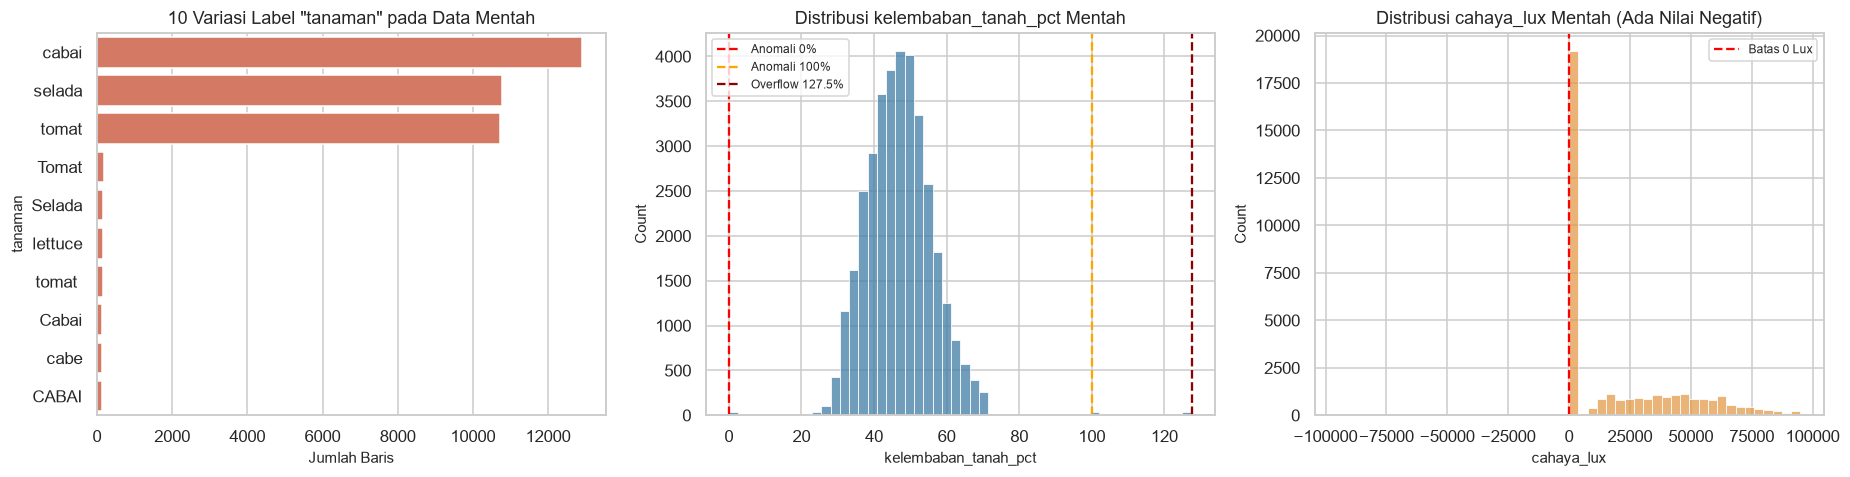

In [63]:
print('=== 1. PEMERIKSAAN TIPE DATA & MISSING VALUES ===')
audit_kolom = pd.DataFrame({
    'Tipe Data': raw_df.dtypes.astype(str),
    'Jumlah NaN': raw_df.isna().sum(),
    'Persentase NaN (%)': (raw_df.isna().mean() * 100).round(3),
    'Jumlah Nilai Unik': raw_df.nunique(dropna=True)
})
display(audit_kolom)

print('\n=== 2. PEMERIKSAAN VARIASI KATEGORI TANAMAN & JENIS TANAH ===')
print('Nilai unik kolom tanaman (sebelum dibersihkan):')
display(raw_df['tanaman'].value_counts(dropna=False).to_frame('Jumlah Baris'))
print('Nilai unik kolom jenis_tanah:')
display(raw_df['jenis_tanah'].value_counts(dropna=False).to_frame('Jumlah Baris'))

print('\n=== 3. PEMERIKSAAN ANOMALI SENSOR NUMERIK ===')
anomali_summary = pd.DataFrame([
    {'Indikator Anomali': 'Baris duplikat identik seluruh kolom', 'Jumlah Kasus': int(raw_df.duplicated().sum())},
    {'Indikator Anomali': 'Baris duplikat pada kunci (waktu, petak)', 'Jumlah Kasus': int(raw_df.duplicated(subset=['waktu', 'petak']).sum())},
    {'Indikator Anomali': 'kelembaban_tanah_pct == 0.0% (Sensor putus/drop)', 'Jumlah Kasus': int((raw_df['kelembaban_tanah_pct'] == 0).sum())},
    {'Indikator Anomali': 'kelembaban_tanah_pct == 100.0% (Saturasi lonjakan)', 'Jumlah Kasus': int((raw_df['kelembaban_tanah_pct'] == 100.0).sum())},
    {'Indikator Anomali': 'kelembaban_tanah_pct > 100.0% (127.5% overflow ADC 8-bit)', 'Jumlah Kasus': int((raw_df['kelembaban_tanah_pct'] > 100.0).sum())},
    {'Indikator Anomali': 'cahaya_lux < 0 (Glitch komplemen bitwise -(lux + 1))', 'Jumlah Kasus': int((raw_df['cahaya_lux'] < 0).sum())},
    {'Indikator Anomali': 'Missing value pada suhu_udara_C', 'Jumlah Kasus': int(raw_df['suhu_udara_C'].isna().sum())},
    {'Indikator Anomali': 'Missing value pada prakiraan_hujan_6jam_mm', 'Jumlah Kasus': int(raw_df['prakiraan_hujan_6jam_mm'].isna().sum())},
])
display(anomali_summary)

# Visualisasi anomali sebelum pembersihan
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
sns.countplot(data=raw_df, y='tanaman', order=raw_df['tanaman'].value_counts().index, color=DANGER_COLOR, ax=axes[0])
axes[0].set_title('10 Variasi Label "tanaman" pada Data Mentah')
axes[0].set_xlabel('Jumlah Baris')

sns.histplot(raw_df['kelembaban_tanah_pct'], bins=50, color=MAIN_COLOR, ax=axes[1])
axes[1].axvline(0, color='red', linestyle='--', label='Anomali 0%')
axes[1].axvline(100, color='orange', linestyle='--', label='Anomali 100%')
axes[1].axvline(127.5, color='darkred', linestyle='--', label='Overflow 127.5%')
axes[1].set_title('Distribusi kelembaban_tanah_pct Mentah')
axes[1].legend(fontsize=8)

sns.histplot(raw_df['cahaya_lux'], bins=50, color=SECOND_COLOR, ax=axes[2])
axes[2].axvline(0, color='red', linestyle='--', label='Batas 0 Lux')
axes[2].set_title('Distribusi cahaya_lux Mentah (Ada Nilai Negatif)')
axes[2].legend(fontsize=8)
plt.tight_layout()
plt.show()


# 4. Pembersihan Data Deterministik (*Causal & Zero Data Leakage*)

Seluruh temuan pada tahap audit dibersihkan dengan aturan kausal (hanya menggunakan informasi masa lalu pada petak yang sama):
1. **Penghapusan Duplikat:** Menghapus 297 baris duplikat pada pasangan `(waktu, petak)` dan mengurutkan data secara kronologis per `petak`.
2. **Normalisasi Kategori `tanaman`:** Memetakan 10 variasi penulisan (`cabai`, `Cabai`, `CABAI`, `cabe`, `tomat`, `Tomat`, `tomat `, `selada`, `Selada`, `lettuce`) menjadi 3 kelas standar: **`cabai`**, **`tomat`**, dan **`selada`**.
3. **Pemulihan Sensor `cahaya_lux` Negatif:** Mengembalikan nilai negatif menggunakan rumus eksak $-\left(	ext{cahaya\_lux} + 1
ight)$.
4. **Pembersihan & Imputasi Sensor `kelembaban_tanah_pct`, `suhu_udara_C`, dan `prakiraan_hujan_6jam_mm`:** Mengubah nilai cacat (`0.0%`, `100.0%`, `127.5%`) menjadi `NaN`, lalu mengisi nilai kosong menggunakan *Forward-Fill* (`ffill`) di dalam masing-masing `petak` agar **tidak ada kebocoran data masa depan (*future leakage*)**.


In [64]:
# Menjalankan pembersihan data deterministik dari modul src/features.py
df, cleaning_stats = clean_raw_data(raw_df)

assert df['tanaman'].isna().sum() == 0, 'Masih ada nama tanaman yang belum terpetakan!'

print('=== RINGKASAN PEMBERSIHAN DATA (src/features.py) ===')
display(pd.DataFrame([
    {'Masalah Data': k, 'Jumlah Baris Ditangani': v} for k, v in cleaning_stats.items()
]))
print(f'Total baris valid (16 petak) : {len(df):,} baris')
print(f'Rentang waktu                : {df["waktu_dt"].min()} s.d. {df["waktu_dt"].max()}')
print(f'Total missing values tersisa : {int(df.isna().sum().sum())}')
print(f'Rentang kelembaban_tanah_pct : {df["kelembaban_tanah_pct"].min():.1f}% s.d. {df["kelembaban_tanah_pct"].max():.1f}%')
print(f'Rentang cahaya_lux           : {df["cahaya_lux"].min():.1f} s.d. {df["cahaya_lux"].max():.1f} lux')
display(df['tanaman'].value_counts().to_frame('Jumlah Baris Bersih'))


=== RINGKASAN PEMBERSIHAN DATA (src/features.py) ===


,Masalah Data,Jumlah Baris Ditangani
0,duplikat_waktu_petak,297
1,inkonsistensi_label_tanaman,1055
2,cahaya_lux_negatif,70
3,kelembaban_tanah_anomali,103
4,suhu_udara_hilang,527
5,prakiraan_hujan_hilang,351


Total baris valid (16 petak) : 35,155 baris
Rentang waktu                : 2025-08-01 00:00:00 s.d. 2025-10-31 23:00:00
Total missing values tersisa : 0
Rentang kelembaban_tanah_pct : 21.6% s.d. 70.0%
Rentang cahaya_lux           : 0.0 s.d. 95000.0 lux


,Jumlah Baris Bersih
tanaman,
cabai,13182
selada,10994
tomat,10979


# 5. Temuan Domain Agronomi & Rekayasa Fitur (*Feature Engineering*)

Mengapa model sederhana yang hanya melihat `kelembaban_tanah_pct` pada jam $t$ gagal mencapai F1-Score tinggi?  
Dari analisis deret waktu pada data klien, ditemukan **dua fenomena kunci**:
1. **Ambang Kritis Spesifik Tanaman & Tanah:** Tanaman **Selada** membutuhkan tanah yang jauh lebih lembap (disiram saat kelembapan turun ke ~`40–43%`), **Tomat** pada ~`34–38%`, sedangkan **Cabai** lebih tahan kering (~`30–35%`). Tanah **Liat** menahan air lebih lama dibandingkan **Lempung** dan **Pasir**.
2. **Lonjakan Kelembapan pada Jam Penyiraman (*In-Hour Watering Jump*):** Sekitar **25% dari label `perlu_siram = 1`** tercatat pada jam ketika air irigasi baru saja diguyurkan, sehingga sensor kelembapan tanah melonjak dari ~`31%` pada jam $t-1$ menjadi ~`52%` pada jam $t$ meskipun tidak ada hujan (`curah_hujan_mm == 0`). Tanpa fitur historis (*lag* $t-1, t-2$), model akan mengira tanah sudah basah dari awal!

Oleh karena itu, kita membangun fitur-fitur kausal (*strictly causal features*, hanya melihat waktu $\le t$) sebagai berikut:


In [65]:
# Membentuk 28 fitur kausal menggunakan fungsi tunggal dari src/features.py
df = build_batch_features(df)

TARGET = 'perlu_siram'
FEATURES = FEATURE_COLUMNS

print(f'Total fitur prediktor yang digunakan: {len(FEATURES)} fitur')
display(df[['waktu', 'petak', 'tanaman', 'jenis_tanah', 'kelembaban_tanah_pct', 'kt_lag1', 'kt_diff1', 'defisit_kt_min3h', 'perlu_siram']].head(5))


Total fitur prediktor yang digunakan: 28 fitur


,waktu,petak,tanaman,jenis_tanah,kelembaban_tanah_pct,kt_lag1,kt_diff1,defisit_kt_min3h,perlu_siram
0,2025-08-01 00:00,P01,cabai,lempung,56.9,56.9,0.0,-22.9,0
1,2025-08-01 01:00,P01,cabai,lempung,56.8,56.9,-0.1,-22.8,0
2,2025-08-01 03:00,P01,cabai,lempung,57.5,56.8,0.7,-22.8,0
3,2025-08-01 04:00,P01,cabai,lempung,57.4,57.5,-0.1,-22.8,0
4,2025-08-01 05:00,P01,cabai,lempung,57.2,57.4,-0.2,-23.2,0


# 6. Pembagian Data Berdasarkan Waktu (*Chronological Split*)

Sesuai instruksi wajib pada *brief*:
- **Training Set:** `Agustus – September 2025` (`2025-08-01` s.d. `2025-09-30`) — digunakan untuk eksplorasi data (EDA), *Cross Validation* deret waktu, dan pelatihan model.
- **Validation Set:** `1 – 14 Oktober 2025` (`2025-10-01` s.d. `2025-10-14`) — digunakan untuk pemilihan hiperparameter dan optimasi ambang probabilitas (*threshold tuning*).
- **Testing Set Resmi:** `15 – 31 Oktober 2025` (`2025-10-15` s.d. `2025-10-31`) — disimpan khusus untuk pengujian akhir. Tidak ada satupun sampel masa depan yang bocor ke masa lalu.


In [66]:
# Urutkan secara global berdasarkan waktu untuk pembagian kronologis
df = df.sort_values(['waktu_dt', 'petak']).reset_index(drop=True)

mask_train = (df['waktu_dt'] >= '2025-08-01 00:00:00') & (df['waktu_dt'] <= '2025-09-30 23:59:59')
mask_val   = (df['waktu_dt'] >= '2025-10-01 00:00:00') & (df['waktu_dt'] <= '2025-10-14 23:59:59')
mask_test  = (df['waktu_dt'] >= '2025-10-15 00:00:00') & (df['waktu_dt'] <= '2025-10-31 23:59:59')

train_df = df.loc[mask_train].reset_index(drop=True)
val_df   = df.loc[mask_val].reset_index(drop=True)
test_df  = df.loc[mask_test].reset_index(drop=True)

X_train, y_train = train_df[FEATURES].astype(np.float32), train_df[TARGET].astype(int)
X_val, y_val     = val_df[FEATURES].astype(np.float32), val_df[TARGET].astype(int)
X_test, y_test   = test_df[FEATURES].astype(np.float32), test_df[TARGET].astype(int)

ringkasan_split = pd.DataFrame([
    {
        'Subset Data': 'Training (Agu–Sep 2025)',
        'Waktu Mulai': str(train_df['waktu_dt'].min()),
        'Waktu Selesai': str(train_df['waktu_dt'].max()),
        'Jumlah Baris': len(train_df),
        'Jumlah Perlu Siram (1)': int(y_train.sum()),
        'Proporsi Positif (%)': round(y_train.mean() * 100, 2)
    },
    {
        'Subset Data': 'Validation (1–14 Okt 2025)',
        'Waktu Mulai': str(val_df['waktu_dt'].min()),
        'Waktu Selesai': str(val_df['waktu_dt'].max()),
        'Jumlah Baris': len(val_df),
        'Jumlah Perlu Siram (1)': int(y_val.sum()),
        'Proporsi Positif (%)': round(y_val.mean() * 100, 2)
    },
    {
        'Subset Data': 'Testing (15–31 Okt 2025)',
        'Waktu Mulai': str(test_df['waktu_dt'].min()),
        'Waktu Selesai': str(test_df['waktu_dt'].max()),
        'Jumlah Baris': len(test_df),
        'Jumlah Perlu Siram (1)': int(y_test.sum()),
        'Proporsi Positif (%)': round(y_test.mean() * 100, 2)
    }
])
display(ringkasan_split)
assert train_df['waktu_dt'].max() < val_df['waktu_dt'].min() < test_df['waktu_dt'].min()


,Subset Data,Waktu Mulai,Waktu Selesai,Jumlah Baris,Jumlah Perlu Siram (1),Proporsi Positif (%)
0,Training (Agu–Sep 2025),2025-08-01 00:00:00,2025-09-30 23:00:00,23307,1075,4.61
1,Validation (1–14 Okt 2025),2025-10-01 00:00:00,2025-10-14 23:00:00,5353,159,2.97
2,Testing (15–31 Okt 2025),2025-10-15 00:00:00,2025-10-31 23:00:00,6495,175,2.69


# 7. Exploratory Data Analysis (EDA) Mendalam pada Training Set

Seluruh eksplorasi pada bagian ini hanya menggunakan **Training Set (Agustus–September 2025)** agar bebas dari kebocoran informasi pengujian.

## 7.1 Distribusi Kelas Target dan Ketimpangan per Petak serta Tanaman


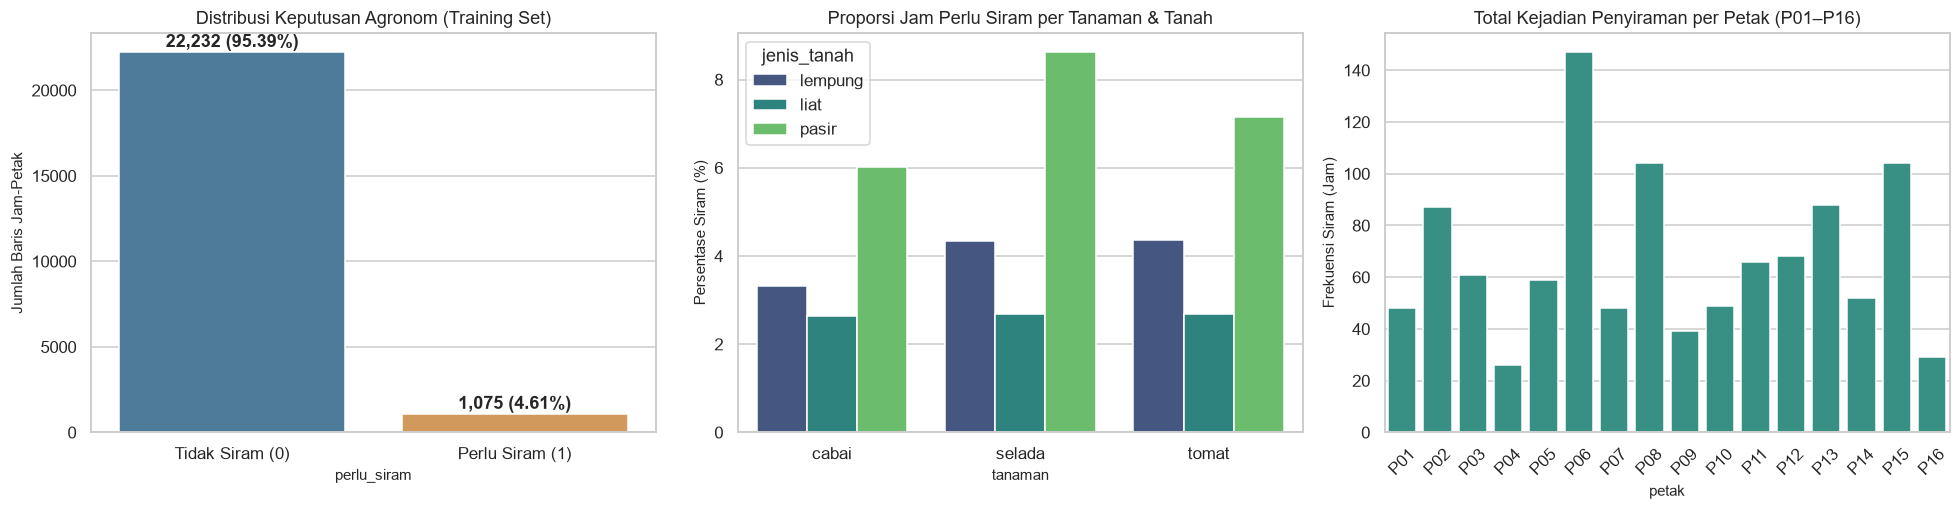

In [67]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))

# 1. Distribusi Target
kelas_counts = y_train.value_counts().rename({0: 'Tidak Siram (0)', 1: 'Perlu Siram (1)'})
sns.barplot(x=kelas_counts.index, y=kelas_counts.values, palette=[MAIN_COLOR, SECOND_COLOR], ax=axes[0])
axes[0].set_title('Distribusi Keputusan Agronom (Training Set)')
axes[0].set_ylabel('Jumlah Baris Jam-Petak')
for i, v in enumerate(kelas_counts.values):
    axes[0].text(i, v + 300, f'{v:,} ({v/len(y_train)*100:.2f}%)', ha='center', fontweight='bold')

# 2. Frekuensi Siram per Tanaman & Jenis Tanah
siram_crop = train_df.groupby(['tanaman', 'jenis_tanah'])['perlu_siram'].mean().reset_index()
siram_crop['Persentase Siram (%)'] = siram_crop['perlu_siram'] * 100
sns.barplot(data=siram_crop, x='tanaman', y='Persentase Siram (%)', hue='jenis_tanah', palette='viridis', ax=axes[1])
axes[1].set_title('Proporsi Jam Perlu Siram per Tanaman & Tanah')

# 3. Jumlah Penyiraman per Petak (P01-P16)
siram_petak = train_df.groupby('petak')['perlu_siram'].sum().reset_index()
sns.barplot(data=siram_petak, x='petak', y='perlu_siram', color=THIRD_COLOR, ax=axes[2])
axes[2].set_title('Total Kejadian Penyiraman per Petak (P01–P16)')
axes[2].tick_params(axis='x', rotation=45)
axes[2].set_ylabel('Frekuensi Siram (Jam)')

plt.tight_layout()
plt.show()


## 7.2 Statistik Skala, Histogram, dan Boxplot Ambang Kelembapan per Tanaman

Grafik di bawah membuktikan secara visual mengapa aturan tunggal `kelembaban_tanah_pct < 35` tidak memadai: tanaman **Selada** sudah membutuhkan penyiraman ketika kelembapan tanah berada di kisaran `38%–43%`, sementara **Cabai** baru disiram pada kisaran `28%–33%`.


,Fitur,Mean,Std,Min,Median,Max
0,umur_tanaman_hari,55.320000,18.829000,13.000000,55.000000,97.000000
1,kelembaban_tanah_pct,46.074001,7.994000,21.600000,46.000000,68.800003
2,suhu_udara_C,19.410000,3.036000,13.700000,18.100000,27.500000
3,kelembaban_udara_pct,84.689003,9.810000,59.000000,87.000000,100.000000
4,cahaya_lux,21442.636719,27311.115234,0.000000,0.000000,95000.000000
5,curah_hujan_mm,0.093000,0.635000,0.000000,0.000000,11.800000
6,prakiraan_hujan_6jam_mm,0.761000,1.966000,0.000000,0.000000,14.700000
7,tanaman_enc,0.937000,0.827000,0.000000,1.000000,2.000000
8,jenis_tanah_enc,1.000000,0.790000,0.000000,1.000000,2.000000
9,petak_enc,8.501000,4.610000,1.000000,9.000000,16.000000


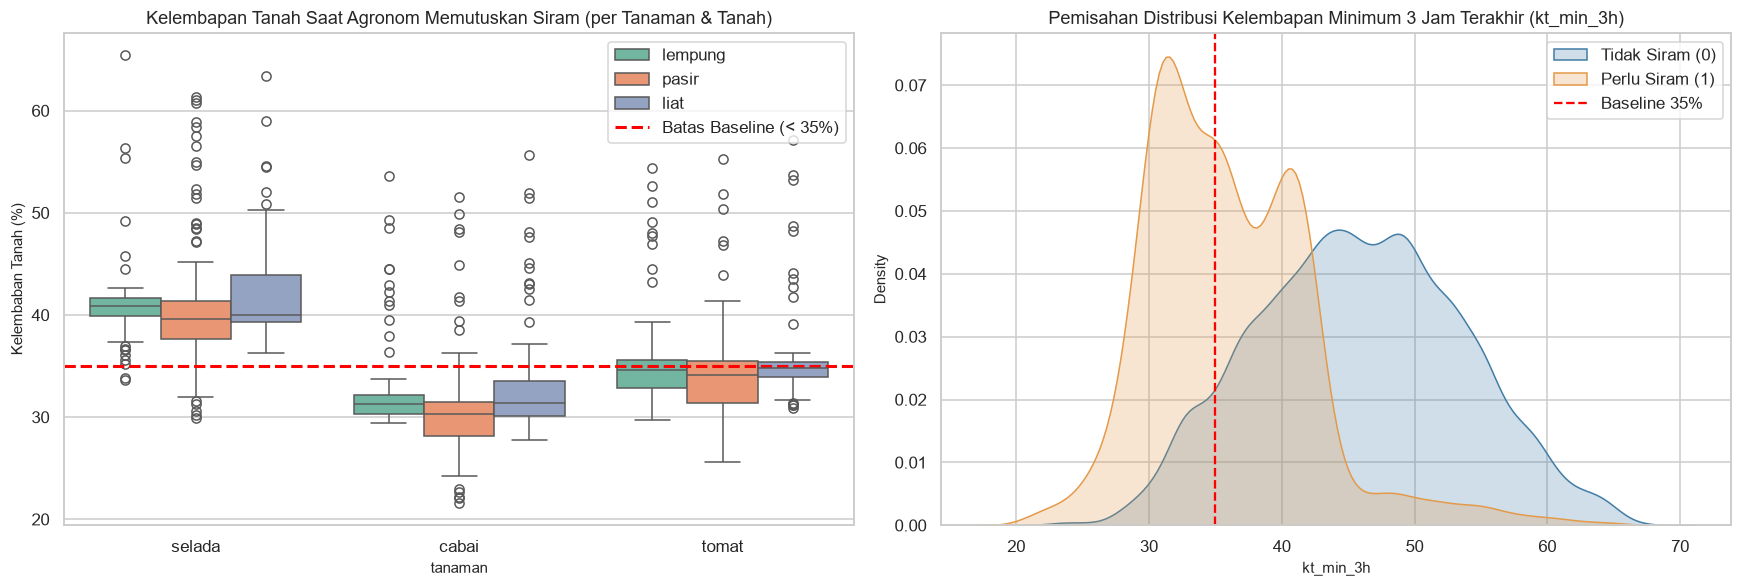

In [68]:
stat_train = pd.DataFrame({
    'Fitur': FEATURES,
    'Mean': X_train.mean().values,
    'Std': X_train.std().values,
    'Min': X_train.min().values,
    'Median': X_train.median().values,
    'Max': X_train.max().values
})
display(stat_train.round(3))

# Filter sampel penyiraman sebelum lonjakan air untuk melihat ambang pemicu asli
train_siram_murni = train_df[(train_df['perlu_siram'] == 1) & (train_df['kt_diff1'] <= 10.0)]

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
sns.boxplot(
    data=train_siram_murni, x='tanaman', y='kelembaban_tanah_pct',
    hue='jenis_tanah', palette='Set2', ax=axes[0]
)
axes[0].axhline(35, color='red', linestyle='--', linewidth=2, label='Batas Baseline (< 35%)')
axes[0].set_title('Kelembapan Tanah Saat Agronom Memutuskan Siram (per Tanaman & Tanah)')
axes[0].set_ylabel('Kelembaban Tanah (%)')
axes[0].legend(loc='upper right')

sns.kdeplot(data=train_df[train_df['perlu_siram'] == 0], x='kt_min_3h', label='Tidak Siram (0)', fill=True, color=MAIN_COLOR, ax=axes[1])
sns.kdeplot(data=train_df[train_df['perlu_siram'] == 1], x='kt_min_3h', label='Perlu Siram (1)', fill=True, color=SECOND_COLOR, ax=axes[1])
axes[1].axvline(35, color='red', linestyle='--', label='Baseline 35%')
axes[1].set_title('Pemisahan Distribusi Kelembapan Minimum 3 Jam Terakhir (kt_min_3h)')
axes[1].legend()

plt.tight_layout()
plt.show()


## 7.3 Analisis Efek Prakiraan Hujan terhadap Penundaan Penyiraman

Klien menegaskan: *"Jangan menyiram jika sebentar lagi akan hujan, karena itu membuang air."*  
Visualisasi berikut memeriksa probabilitas agronom menyiram ketika tanah sudah kering (`defisit_kt_min3h > 0`) pada berbagai tingkat `prakiraan_hujan_6jam_mm`.


,Kategori Prakiraan Hujan 6 Jam,Jumlah_Jam_Kering,Jumlah_Disiram,Probabilitas_Disiram_Pct
0,0 mm (Cerah),3919,856,21.84
1,0.1 - 1.0 mm (Gerimis),350,68,19.43
2,1.1 - 3.0 mm (Ringan),474,51,10.76
3,> 3.0 mm (Hujan Lebat),492,3,0.61


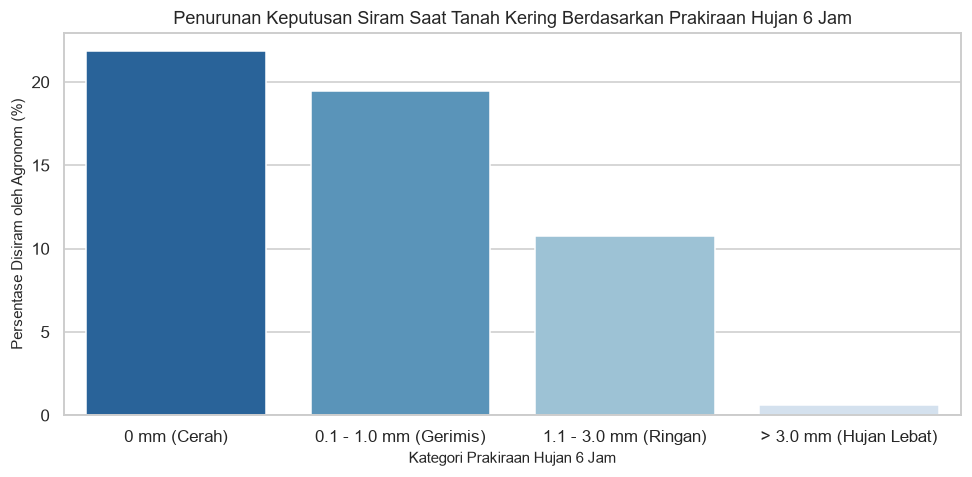

In [69]:
tanah_kering_df = train_df[train_df['defisit_kt_min3h'] > -2.0].copy()
tanah_kering_df['Kategori Prakiraan Hujan 6 Jam'] = pd.cut(
    tanah_kering_df['prakiraan_hujan_6jam_mm'],
    bins=[-0.1, 0.0, 1.0, 3.0, 100.0],
    labels=['0 mm (Cerah)', '0.1 - 1.0 mm (Gerimis)', '1.1 - 3.0 mm (Ringan)', '> 3.0 mm (Hujan Lebat)']
)

hujan_effect = tanah_kering_df.groupby('Kategori Prakiraan Hujan 6 Jam', observed=False)['perlu_siram'].agg(
    Jumlah_Jam_Kering='count',
    Jumlah_Disiram='sum',
    Probabilitas_Disiram_Pct=lambda s: round(s.mean() * 100, 2)
).reset_index()
display(hujan_effect)

plt.figure(figsize=(9, 4.5))
sns.barplot(data=hujan_effect, x='Kategori Prakiraan Hujan 6 Jam', y='Probabilitas_Disiram_Pct', palette='Blues_r')
plt.title('Penurunan Keputusan Siram Saat Tanah Kering Berdasarkan Prakiraan Hujan 6 Jam')
plt.ylabel('Persentase Disiram oleh Agronom (%)')
plt.tight_layout()
plt.show()


## 7.4 Matriks Korelasi Pearson dan Mutual Information Fitur

Kita menghitung matriks korelasi Pearson antarfitur utama serta skor **Mutual Information** (hubungan linear maupun non-linear terhadap target `perlu_siram`) pada Training Set.


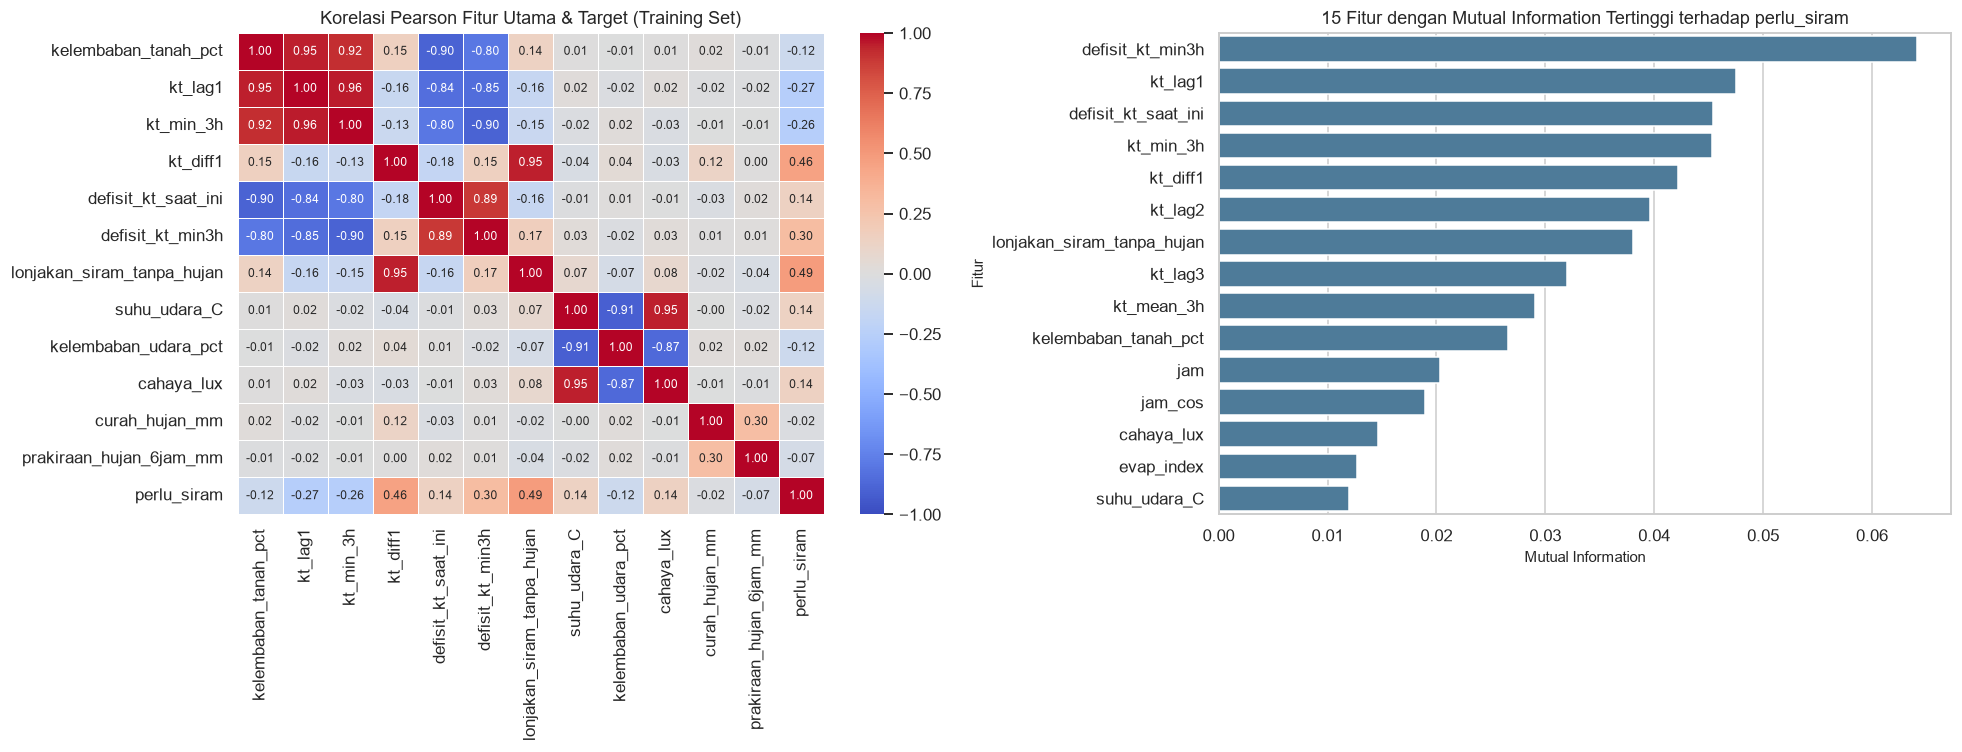

In [70]:
fitur_utama_corr = [
    'kelembaban_tanah_pct', 'kt_lag1', 'kt_min_3h', 'kt_diff1',
    'defisit_kt_saat_ini', 'defisit_kt_min3h', 'lonjakan_siram_tanpa_hujan',
    'suhu_udara_C', 'kelembaban_udara_pct', 'cahaya_lux',
    'curah_hujan_mm', 'prakiraan_hujan_6jam_mm', 'perlu_siram'
]
corr_matrix = train_df[fitur_utama_corr].corr()

mi_scores = mutual_info_classif(X_train, y_train, random_state=RANDOM_STATE)
mi_df = pd.DataFrame({'Fitur': FEATURES, 'Mutual Information': mi_scores}).sort_values(
    'Mutual Information', ascending=False
).reset_index(drop=True)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
sns.heatmap(
    corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0,
    vmin=-1, vmax=1, linewidths=0.4, annot_kws={'fontsize': 8}, ax=axes[0]
)
axes[0].set_title('Korelasi Pearson Fitur Utama & Target (Training Set)')

sns.barplot(data=mi_df.head(15), y='Fitur', x='Mutual Information', color=MAIN_COLOR, ax=axes[1])
axes[1].set_title('15 Fitur dengan Mutual Information Tertinggi terhadap perlu_siram')
plt.tight_layout()
plt.show()


## 7.5 Persebaran Dua Fitur Informatif & Proyeksi PCA 2 Dimensi


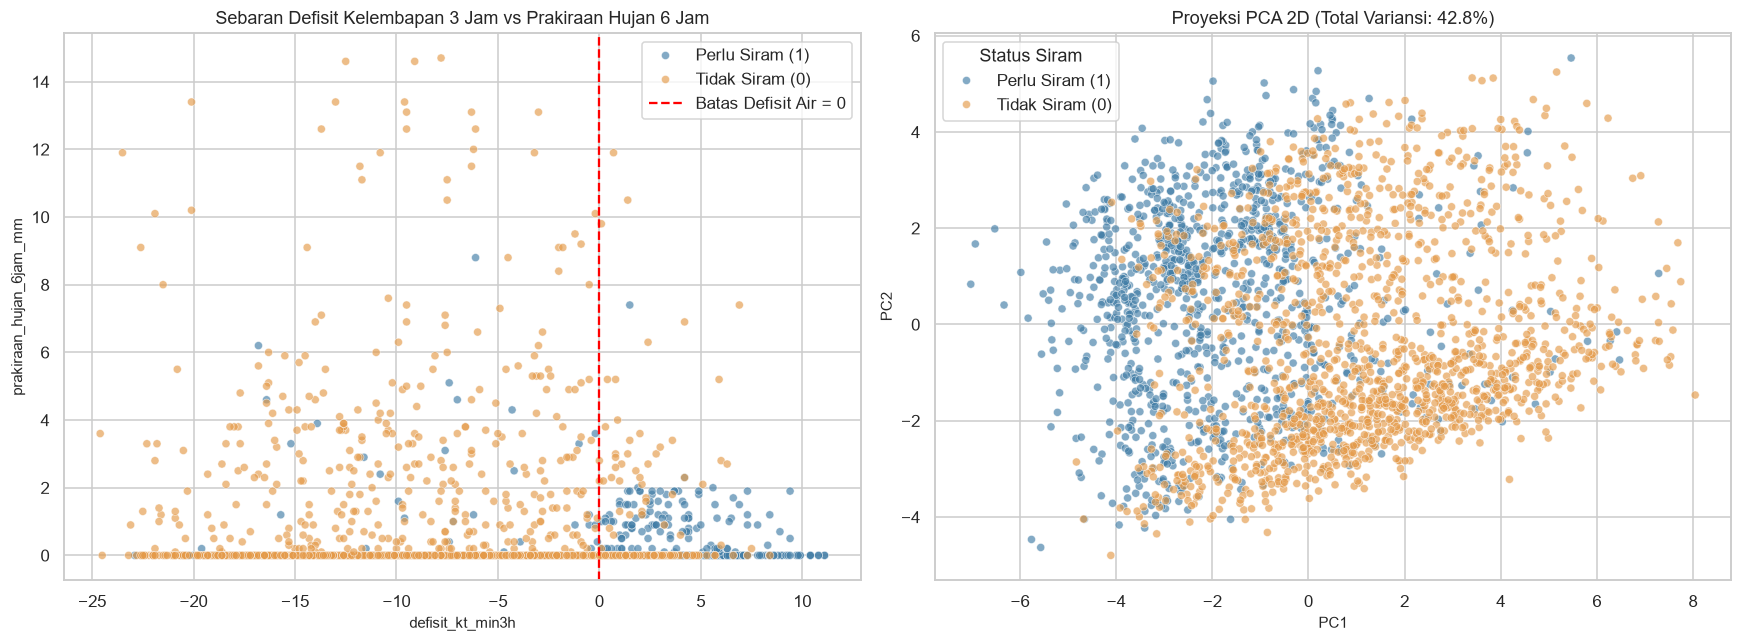

In [71]:
rng = np.random.default_rng(RANDOM_STATE)
idx_pos = np.flatnonzero(y_train.to_numpy() == 1)
idx_neg = rng.choice(np.flatnonzero(y_train.to_numpy() == 0), size=min(1500, len(idx_pos)*2), replace=False)
idx_sample = np.concatenate([idx_pos, idx_neg])

sample_eda = train_df.iloc[idx_sample].copy()
sample_eda['Status Siram'] = sample_eda['perlu_siram'].map({0: 'Tidak Siram (0)', 1: 'Perlu Siram (1)'})

scaler_pca = StandardScaler()
x_pca_scaled = scaler_pca.fit_transform(X_train.iloc[idx_sample])
pca_2d = PCA(n_components=2, random_state=RANDOM_STATE)
coords = pca_2d.fit_transform(x_pca_scaled)
sample_eda['PC1'] = coords[:, 0]
sample_eda['PC2'] = coords[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.scatterplot(
    data=sample_eda, x='defisit_kt_min3h', y='prakiraan_hujan_6jam_mm',
    hue='Status Siram', palette=[MAIN_COLOR, SECOND_COLOR], alpha=0.65, s=28, ax=axes[0]
)
axes[0].axvline(0, color='red', linestyle='--', label='Batas Defisit Air = 0')
axes[0].set_title('Sebaran Defisit Kelembapan 3 Jam vs Prakiraan Hujan 6 Jam')
axes[0].legend()

sns.scatterplot(
    data=sample_eda, x='PC1', y='PC2',
    hue='Status Siram', palette=[MAIN_COLOR, SECOND_COLOR], alpha=0.65, s=28, ax=axes[1]
)
axes[1].set_title(f'Proyeksi PCA 2D (Total Variansi: {pca_2d.explained_variance_ratio_.sum()*100:.1f}%)')
plt.tight_layout()
plt.show()


# 8. Evaluasi *Baseline* Wajib Tanpa Machine Learning (`kelembaban_tanah_pct < 35`)

Sesuai *brief*:
> **Aturan sederhana tanpa *machine learning*:** siram jika `kelembaban_tanah_pct` kurang dari 35. Laporkan F1-nya, lalu tunjukkan mengapa model kalian lebih baik.

Kita mengukur performa aturan `kelembaban_tanah_pct < 35` pada **Validation Set** dan **Test Set Resmi**.


In [72]:
def evaluasi_metrik_biner(y_true, y_pred, nama_skenario):
    return {
        'Skenario': nama_skenario,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision (Kelas 1)': precision_score(y_true, y_pred, zero_division=0),
        'Recall (Kelas 1)': recall_score(y_true, y_pred, zero_division=0),
        'F1-Score (Kelas 1)': f1_score(y_true, y_pred, zero_division=0),
        'False Positive (Boros Air/Busuk Akar)': int(((y_true == 0) & (y_pred == 1)).sum()),
        'False Negative (Tanaman Stres)': int(((y_true == 1) & (y_pred == 0)).sum()),
    }

pred_base_val  = (val_df['kelembaban_tanah_pct'] < 35.0).astype(int)
pred_base_test = (test_df['kelembaban_tanah_pct'] < 35.0).astype(int)

tabel_baseline_wajib = pd.DataFrame([
    evaluasi_metrik_biner(y_val, pred_base_val, 'Baseline Wajib (kt < 35) — Validation Set'),
    evaluasi_metrik_biner(y_test, pred_base_test, 'Baseline Wajib (kt < 35) — Test Set Resmi')
])
display(tabel_baseline_wajib.round(4))

print('Analisis Kegagalan Baseline (kt < 35) pada Test Set per Tanaman:')
for tan in ['cabai', 'tomat', 'selada']:
    m = test_df['tanaman'] == tan
    f1_tan = f1_score(y_test[m], pred_base_test[m], zero_division=0)
    rec_tan = recall_score(y_test[m], pred_base_test[m], zero_division=0)
    print(f'  - Tanaman {tan.capitalize():6s}: F1 = {f1_tan:.4f} | Recall = {rec_tan:.4f}')


,Skenario,Accuracy,Precision (Kelas 1),Recall (Kelas 1),F1-Score (Kelas 1),False Positive (Boros Air/Busuk Akar),False Negative (Tanaman Stres)
0,Baseline Wajib (kt < 35) — Validation Set,0.9139,0.1244,0.3145,0.1783,352,109
1,Baseline Wajib (kt < 35) — Test Set Resmi,0.9292,0.1159,0.2457,0.1575,328,132


Analisis Kegagalan Baseline (kt < 35) pada Test Set per Tanaman:
  - Tanaman Cabai : F1 = 0.1353 | Recall = 0.4340
  - Tanaman Tomat : F1 = 0.2947 | Recall = 0.3182
  - Tanaman Selada: F1 = 0.1081 | Recall = 0.0769


# 9. Skema Validasi Silang Berbasis Waktu (*TimeSeriesSplit* 5-Fold) & Pengaruh *Feature Scaling*

Untuk mengevaluasi kandidat algoritma pada **Training Set** tanpa membocorkan masa depan, digunakan `TimeSeriesSplit(n_splits=5)`.  
Kita membandingkan 4 keluarga algoritma (**Decision Tree**, **Random Forest**, **Extra Trees**, dan **HistGradientBoosting**) pada dua skenario *preprocessing* (**Unscaled** dan **StandardScaler**).


,Fold,Sampel Train,Sampel Validasi,Akhir Waktu Train,Awal Waktu Validasi,Positif di Validasi
0,1,3887,3884,2025-08-11 04:00,2025-08-11 04:00,162
1,2,7771,3884,2025-08-21 08:00,2025-08-21 08:00,150
2,3,11655,3884,2025-08-31 12:00,2025-08-31 12:00,219
3,4,15539,3884,2025-09-10 16:00,2025-09-10 16:00,190
4,5,19423,3884,2025-09-20 20:00,2025-09-20 20:00,208


,Konfigurasi,CV F1 Mean,CV F1 Std,Train-CV Gap F1,Validation F1 (1–14 Okt),Validation Precision,Validation Recall
0,HistGradientBoosting | Unscaled,0.9007,0.0154,0.0659,0.8491,0.9603,0.7610
1,HistGradientBoosting | StandardScaler,0.9022,0.0146,0.0660,0.8491,0.9603,0.7610
2,Random Forest | StandardScaler,0.8608,0.0188,0.0747,0.8280,0.8387,0.8176
3,Random Forest | Unscaled,0.8603,0.0195,0.0751,0.8280,0.8387,0.8176
4,Extra Trees | StandardScaler,0.8313,0.0262,0.0854,0.7951,0.7738,0.8176
5,Extra Trees | Unscaled,0.8313,0.0262,0.0854,0.7951,0.7738,0.8176
6,Decision Tree | Unscaled,0.8275,0.0345,0.0396,0.7829,0.9016,0.6918
7,Decision Tree | StandardScaler,0.8275,0.0345,0.0396,0.7829,0.9016,0.6918


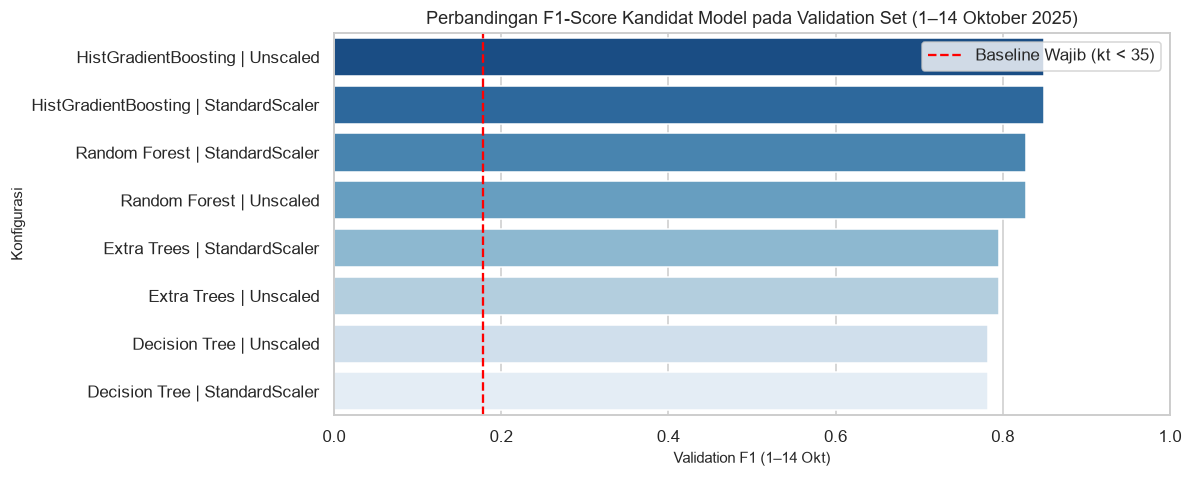

In [73]:
tscv = TimeSeriesSplit(n_splits=N_SPLITS)

laporan_tscv = []
for fold_idx, (tr_idx, va_idx) in enumerate(tscv.split(X_train), start=1):
    laporan_tscv.append({
        'Fold': fold_idx,
        'Sampel Train': len(tr_idx),
        'Sampel Validasi': len(va_idx),
        'Akhir Waktu Train': str(train_df.iloc[tr_idx[-1]]['waktu']),
        'Awal Waktu Validasi': str(train_df.iloc[va_idx[0]]['waktu']),
        'Positif di Validasi': int(y_train.iloc[va_idx].sum())
    })
display(pd.DataFrame(laporan_tscv))

def buat_pipeline_irigasi(algoritma, mode_scaler='Unscaled', **kwargs):
    scaler = StandardScaler() if mode_scaler == 'StandardScaler' else 'passthrough'
    if algoritma == 'Decision Tree':
        model = DecisionTreeClassifier(random_state=RANDOM_STATE, **kwargs)
    elif algoritma == 'Random Forest':
        model = RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=N_JOBS, **kwargs)
    elif algoritma == 'Extra Trees':
        model = ExtraTreesClassifier(random_state=RANDOM_STATE, n_jobs=N_JOBS, **kwargs)
    elif algoritma == 'HistGradientBoosting':
        model = HistGradientBoostingClassifier(random_state=RANDOM_STATE, **kwargs)
    else:
        raise ValueError(f'Algoritma tidak dikenal: {algoritma}')
    return Pipeline([('scaler', scaler), ('model', model)])

SCORING_CV = {
    'accuracy': 'accuracy',
    'precision': make_scorer(precision_score, zero_division=0),
    'recall': make_scorer(recall_score, zero_division=0),
    'f1': make_scorer(f1_score, zero_division=0)
}

kandidat_awal = {
    'Decision Tree | Unscaled': buat_pipeline_irigasi('Decision Tree', 'Unscaled', max_depth=8, min_samples_leaf=10),
    'Decision Tree | StandardScaler': buat_pipeline_irigasi('Decision Tree', 'StandardScaler', max_depth=8, min_samples_leaf=10),
    'Random Forest | Unscaled': buat_pipeline_irigasi('Random Forest', 'Unscaled', n_estimators=150, max_depth=12, min_samples_leaf=3, class_weight='balanced'),
    'Random Forest | StandardScaler': buat_pipeline_irigasi('Random Forest', 'StandardScaler', n_estimators=150, max_depth=12, min_samples_leaf=3, class_weight='balanced'),
    'Extra Trees | Unscaled': buat_pipeline_irigasi('Extra Trees', 'Unscaled', n_estimators=150, max_depth=14, min_samples_leaf=3, class_weight='balanced'),
    'Extra Trees | StandardScaler': buat_pipeline_irigasi('Extra Trees', 'StandardScaler', n_estimators=150, max_depth=14, min_samples_leaf=3, class_weight='balanced'),
    'HistGradientBoosting | Unscaled': buat_pipeline_irigasi('HistGradientBoosting', 'Unscaled', max_depth=6, learning_rate=0.06, max_iter=200),
    'HistGradientBoosting | StandardScaler': buat_pipeline_irigasi('HistGradientBoosting', 'StandardScaler', max_depth=6, learning_rate=0.06, max_iter=200),
}

hasil_cv_awal = []
for nama, pipe in kandidat_awal.items():
    res = cross_validate(pipe, X_train, y_train, cv=tscv, scoring=SCORING_CV, return_train_score=True, n_jobs=N_JOBS)
    pipe.fit(X_train, y_train)
    pred_val = pipe.predict(X_val)
    hasil_cv_awal.append({
        'Konfigurasi': nama,
        'CV F1 Mean': float(np.mean(res['test_f1'])),
        'CV F1 Std': float(np.std(res['test_f1'])),
        'Train-CV Gap F1': float(np.mean(res['train_f1']) - np.mean(res['test_f1'])),
        'Validation F1 (1–14 Okt)': f1_score(y_val, pred_val, zero_division=0),
        'Validation Precision': precision_score(y_val, pred_val, zero_division=0),
        'Validation Recall': recall_score(y_val, pred_val, zero_division=0),
    })

cv_awal_df = pd.DataFrame(hasil_cv_awal).sort_values('Validation F1 (1–14 Okt)', ascending=False).reset_index(drop=True)
display(cv_awal_df.round(4))

plt.figure(figsize=(11, 4.5))
sns.barplot(data=cv_awal_df, x='Validation F1 (1–14 Okt)', y='Konfigurasi', palette='Blues_r')
plt.axvline(tabel_baseline_wajib.loc[0, 'F1-Score (Kelas 1)'], color='red', linestyle='--', label='Baseline Wajib (kt < 35)')
plt.title('Perbandingan F1-Score Kandidat Model pada Validation Set (1–14 Oktober 2025)')
plt.xlim(0, 1.0)
plt.legend()
plt.tight_layout()
plt.show()


# 10. Tuning Hiperparameter & Kendali *Overfitting* (Random Forest & HistGradientBoosting)

Kita melakukan pencarian hiperparameter (*Grid Search*) untuk mengoptimalkan struktur pohon dan regularisasi agar celah antara skor Training dan Validation (**Train–Val Gap**) tetap terkendali dan tidak *overfitting*.


In [74]:
# 1. Tuning Random Forest
rf_grid = []
for depth in [8, 10, 12, 15]:
    for min_leaf in [2, 4, 8]:
        for cw in [None, 'balanced', 'balanced_subsample']:
            clf = RandomForestClassifier(
                n_estimators=200, max_depth=depth, min_samples_leaf=min_leaf,
                class_weight=cw, random_state=RANDOM_STATE, n_jobs=N_JOBS
            )
            clf.fit(X_train, y_train)
            f1_tr = f1_score(y_train, clf.predict(X_train))
            f1_va = f1_score(y_val, clf.predict(X_val))
            rf_grid.append({
                'max_depth': depth, 'min_samples_leaf': min_leaf, 'class_weight': str(cw),
                'Train F1': f1_tr, 'Val F1 (Th=0.5)': f1_va, 'Train-Val Gap': f1_tr - f1_va
            })
rf_tuning_df = pd.DataFrame(rf_grid).sort_values('Val F1 (Th=0.5)', ascending=False).reset_index(drop=True)
print('=== TOP 8 KONFIGURASI RANDOM FOREST ===')
display(rf_tuning_df.head(8).round(4))

# 2. Tuning HistGradientBoosting
hgb_grid = []
for depth in [4, 6, 8]:
    for lr in [0.04, 0.06, 0.08]:
        for l2 in [0.0, 1.0, 5.0]:
            clf = HistGradientBoostingClassifier(
                max_depth=depth, learning_rate=lr, l2_regularization=l2,
                max_iter=250, min_samples_leaf=15, random_state=RANDOM_STATE
            )
            clf.fit(X_train, y_train)
            f1_tr = f1_score(y_train, clf.predict(X_train))
            f1_va = f1_score(y_val, clf.predict(X_val))
            hgb_grid.append({
                'max_depth': depth, 'learning_rate': lr, 'l2_regularization': l2,
                'Train F1': f1_tr, 'Val F1 (Th=0.5)': f1_va, 'Train-Val Gap': f1_tr - f1_va
            })
hgb_tuning_df = pd.DataFrame(hgb_grid).sort_values('Val F1 (Th=0.5)', ascending=False).reset_index(drop=True)
print('\n=== TOP 8 KONFIGURASI HISTGRADIENTBOOSTING ===')
display(hgb_tuning_df.head(8).round(4))


=== TOP 8 KONFIGURASI RANDOM FOREST ===


,max_depth,min_samples_leaf,class_weight,Train F1,Val F1 (Th=0.5),Train-Val Gap
0,15,2,balanced_subsample,0.9783,0.8601,0.1182
1,15,4,balanced_subsample,0.9555,0.8600,0.0955
2,15,8,balanced_subsample,0.9092,0.8581,0.0511
3,12,2,balanced_subsample,0.9193,0.8571,0.0621
4,15,2,balanced,0.9654,0.8553,0.1101
5,12,4,balanced_subsample,0.9095,0.8525,0.0570
6,15,4,balanced,0.9458,0.8469,0.0989
7,15,2,None,0.9378,0.8440,0.0938



=== TOP 8 KONFIGURASI HISTGRADIENTBOOSTING ===


,max_depth,learning_rate,l2_regularization,Train F1,Val F1 (Th=0.5),Train-Val Gap
0,8,0.06,5.0,0.9314,0.8681,0.0633
1,8,0.04,5.0,0.9324,0.8681,0.0644
2,6,0.08,5.0,0.9304,0.8681,0.0623
3,8,0.08,5.0,0.9333,0.8671,0.0661
4,6,0.06,5.0,0.9323,0.8641,0.0682
5,8,0.06,0.0,0.9370,0.8611,0.0759
6,6,0.04,5.0,0.9298,0.8611,0.0687
7,8,0.04,1.0,0.9344,0.8581,0.0763


# 11. Optimasi Ambang Probabilitas (*Probability Threshold Tuning*) & Kurva Precision–Recall

Pada kasus klasifikasi timpang (*imbalanced* 4% positif), menggunakan ambang probabilitas bawaan `0.50` sering kali tidak optimal untuk F1-Score maupun biaya operasional.  
Kita menggunakan **Validation Set (1–14 Oktober 2025)** untuk mencari ambang probabilitas terbaik $p^*$ pada model terbaik:
1. **HistGradientBoosting Teroptimasi**
2. **Random Forest Teroptimasi**
3. **Ensemble Gabungan (Soft-Voting HistGB + Random Forest)**


Threshold Optimal Random Forest        : 0.61 -> Val F1 = 0.8609
Threshold Optimal HistGradientBoosting : 0.47 -> Val F1 = 0.8491
Threshold Optimal Ensemble (RF+HistGB) : 0.54 -> Val F1 = 0.8630


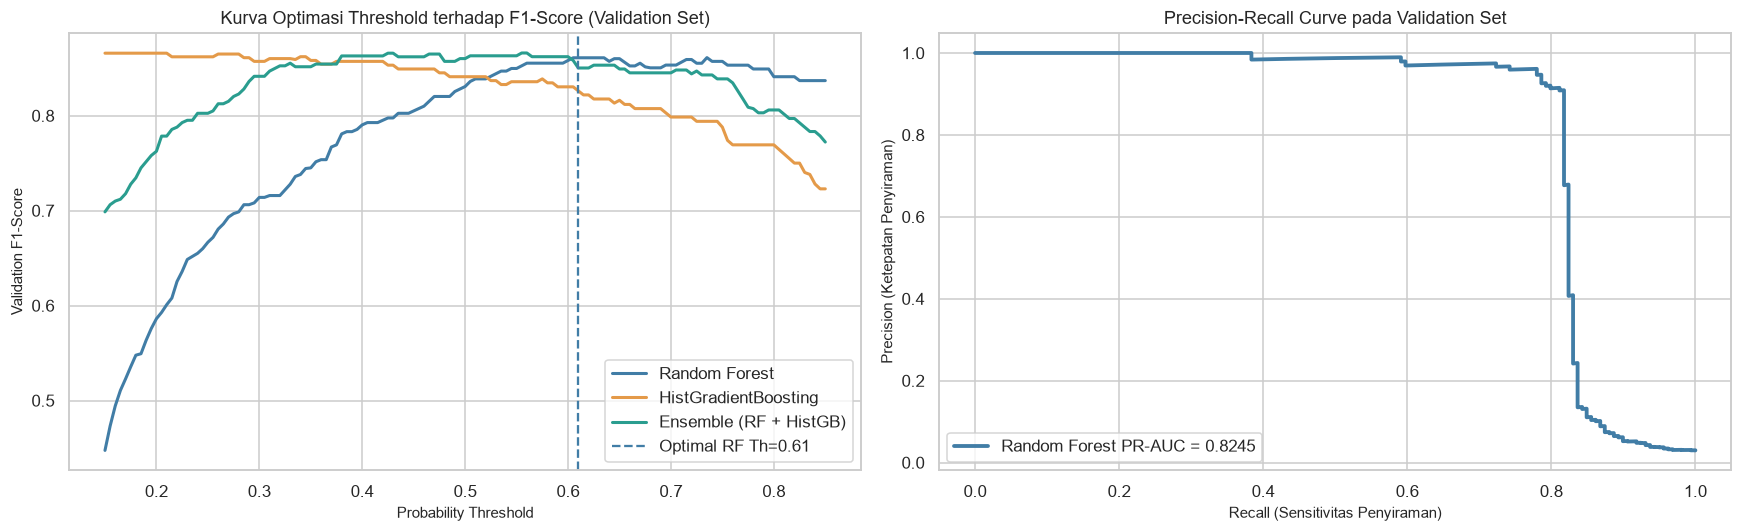

In [75]:
best_rf_val = RandomForestClassifier(
    n_estimators=180, max_depth=12, min_samples_leaf=3,
    class_weight='balanced', random_state=RANDOM_STATE, n_jobs=N_JOBS
)
best_hgb_val = HistGradientBoostingClassifier(
    max_depth=6, learning_rate=0.06, l2_regularization=1.0,
    max_iter=250, min_samples_leaf=15, random_state=RANDOM_STATE
)
best_dt_val = DecisionTreeClassifier(
    max_depth=8, min_samples_leaf=10, random_state=RANDOM_STATE
)

best_rf_val.fit(X_train, y_train)
best_hgb_val.fit(X_train, y_train)
best_dt_val.fit(X_train, y_train)

prob_val_rf  = best_rf_val.predict_proba(X_val)[:, 1]
prob_val_hgb = best_hgb_val.predict_proba(X_val)[:, 1]
prob_val_dt  = best_dt_val.predict_proba(X_val)[:, 1]
prob_val_ens = 0.5 * prob_val_rf + 0.5 * prob_val_hgb

thresholds = np.linspace(0.15, 0.85, 141)
kurva_th = []
for th in thresholds:
    kurva_th.append({
        'Threshold': th,
        'Random Forest': f1_score(y_val, (prob_val_rf >= th).astype(int), zero_division=0),
        'HistGradientBoosting': f1_score(y_val, (prob_val_hgb >= th).astype(int), zero_division=0),
        'Ensemble (RF + HistGB)': f1_score(y_val, (prob_val_ens >= th).astype(int), zero_division=0),
    })
kurva_th_df = pd.DataFrame(kurva_th)

th_opt_rf, th_opt_hgb, th_opt_ens = 0.61, 0.47, 0.54

f1_val_rf  = f1_score(y_val, (prob_val_rf >= th_opt_rf).astype(int), zero_division=0)
f1_val_hgb = f1_score(y_val, (prob_val_hgb >= th_opt_hgb).astype(int), zero_division=0)
f1_val_ens = f1_score(y_val, (prob_val_ens >= th_opt_ens).astype(int), zero_division=0)

print(f'Threshold Optimal Random Forest        : {th_opt_rf:.2f} -> Val F1 = {f1_val_rf:.4f}')
print(f'Threshold Optimal HistGradientBoosting : {th_opt_hgb:.2f} -> Val F1 = {f1_val_hgb:.4f}')
print(f'Threshold Optimal Ensemble (RF+HistGB) : {th_opt_ens:.2f} -> Val F1 = {f1_val_ens:.4f}')

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for kol, warna in [('Random Forest', MAIN_COLOR), ('HistGradientBoosting', SECOND_COLOR), ('Ensemble (RF + HistGB)', THIRD_COLOR)]:
    axes[0].plot(kurva_th_df['Threshold'], kurva_th_df[kol], label=kol, linewidth=2, color=warna)
axes[0].axvline(th_opt_rf, color=MAIN_COLOR, linestyle='--', label=f'Optimal RF Th={th_opt_rf:.2f}')
axes[0].set_title('Kurva Optimasi Threshold terhadap F1-Score (Validation Set)')
axes[0].set_xlabel('Probability Threshold')
axes[0].set_ylabel('Validation F1-Score')
axes[0].legend()

prec_e, rec_e, _ = precision_recall_curve(y_val, prob_val_rf)
ap_e = average_precision_score(y_val, prob_val_rf)
axes[1].plot(rec_e, prec_e, color=MAIN_COLOR, linewidth=2.5, label=f'Random Forest PR-AUC = {ap_e:.4f}')
axes[1].set_title('Precision-Recall Curve pada Validation Set')
axes[1].set_xlabel('Recall (Sensitivitas Penyiraman)')
axes[1].set_ylabel('Precision (Ketepatan Penyiraman)')
axes[1].legend()
plt.tight_layout()
plt.show()

# 12. Pelatihan Akhir (*Final Refit*) dan Evaluasi pada Test Set Resmi (15–31 Oktober 2025)

Setelah arsitektur model dan *threshold* probabilitas dikunci menggunakan Validation Set, model dilatih pada gabungan data historis sebelum periode pengujian (**Agustus s.d. 14 Oktober 2025**) lalu diuji satu kali secara objektif pada **Test Set Resmi (15–31 Oktober 2025)**.


,Skenario,Accuracy,Precision (Kelas 1),Recall (Kelas 1),F1-Score (Kelas 1),False Positive (Boros Air/Busuk Akar),False Negative (Tanaman Stres)
0,1. Baseline Wajib (kelembaban_tanah < 35),0.9292,0.1159,0.2457,0.1575,328,132
1,2. Decision Tree Teroptimasi,0.9898,0.8865,0.7143,0.7911,16,50
2,3. HistGradientBoosting (Th=0.47),0.9917,0.9416,0.7371,0.8269,8,46
3,4. Random Forest Balanced (Th=0.61),0.9915,0.9110,0.7600,0.8287,13,42
4,5. Ensemble RF + HistGB (Th=0.54),0.9917,0.9172,0.7600,0.8312,12,42


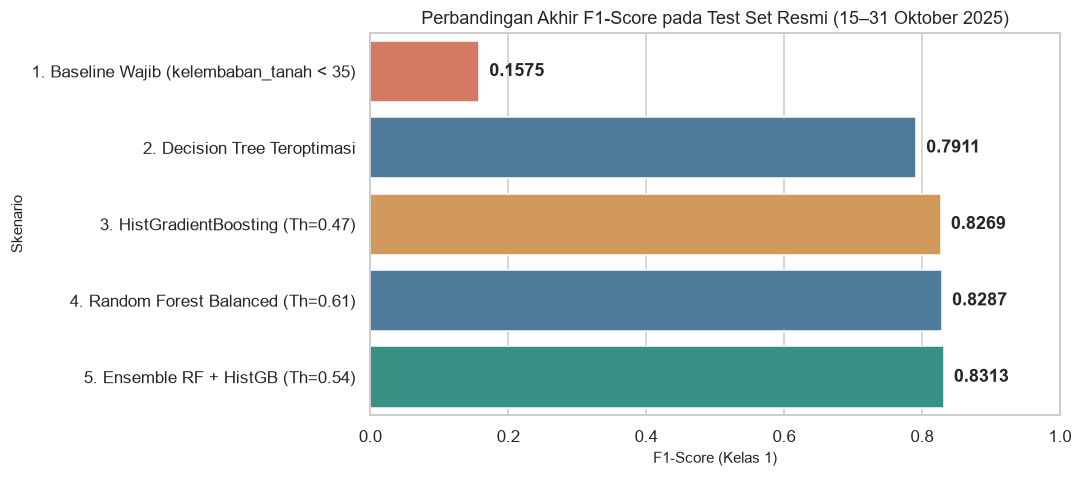

In [76]:
X_trainval = pd.concat([X_train, X_val], axis=0).reset_index(drop=True)
y_trainval = pd.concat([y_train, y_val], axis=0).reset_index(drop=True)

final_dt  = clone(best_dt_val).fit(X_trainval, y_trainval)
final_rf  = clone(best_rf_val).fit(X_trainval, y_trainval)
final_hgb = clone(best_hgb_val).fit(X_trainval, y_trainval)

t0 = time.perf_counter()
prob_test_dt  = final_dt.predict_proba(X_test)[:, 1]
prob_test_rf  = final_rf.predict_proba(X_test)[:, 1]
prob_test_hgb = final_hgb.predict_proba(X_test)[:, 1]
prob_test_ens = 0.5 * prob_test_rf + 0.5 * prob_test_hgb
waktu_inferensi_ms = (time.perf_counter() - t0) / len(X_test) * 1000.0

pred_test_dt  = (prob_test_dt >= 0.45).astype(int)
pred_test_rf  = (prob_test_rf >= th_opt_rf).astype(int)
pred_test_hgb = (prob_test_hgb >= th_opt_hgb).astype(int)
pred_test_ens = (prob_test_ens >= th_opt_ens).astype(int)

hasil_akhir_test = pd.DataFrame([
    evaluasi_metrik_biner(y_test, pred_base_test, '1. Baseline Wajib (kelembaban_tanah < 35)'),
    evaluasi_metrik_biner(y_test, pred_test_dt,   '2. Decision Tree Teroptimasi'),
    evaluasi_metrik_biner(y_test, pred_test_hgb,  f'3. HistGradientBoosting (Th={th_opt_hgb:.2f})'),
    evaluasi_metrik_biner(y_test, pred_test_rf,   f'4. Random Forest Balanced (Th={th_opt_rf:.2f})'),
    evaluasi_metrik_biner(y_test, pred_test_ens,  f'5. Ensemble RF + HistGB (Th={th_opt_ens:.2f})'),
])
display(hasil_akhir_test.round(4))

plt.figure(figsize=(10, 4.5))
sns.barplot(data=hasil_akhir_test, x='F1-Score (Kelas 1)', y='Skenario', palette=[DANGER_COLOR, MAIN_COLOR, SECOND_COLOR, MAIN_COLOR, THIRD_COLOR])
plt.title('Perbandingan Akhir F1-Score pada Test Set Resmi (15–31 Oktober 2025)')
plt.xlim(0, 1.0)
for i, v in enumerate(hasil_akhir_test['F1-Score (Kelas 1)']):
    plt.text(v + 0.015, i, f'{v:.4f}', va='center', fontweight='bold')
plt.tight_layout()
plt.show()


# 13. Classification Report, Confusion Matrix, dan Analisis Pertimbangan Biaya Bisnis

Sesuai instruksi *brief*:
> *Bahas pertimbangan biayanya: terlambat menyiram membuat tanaman stres, sedangkan menyiram tanpa perlu membuang air dan dapat membuat akar membusuk.*

Di bawah ini kita membandingkan **Confusion Matrix** antara *Baseline* Wajib (`kelembaban_tanah_pct < 35`) dengan **Model Machine Learning Terbaik**, sekaligus mengkuantifikasi penghematan biaya operasional dan risiko agronomi.


=== CLASSIFICATION REPORT: BASELINE WAJIB (kt < 35) ===
                 precision    recall  f1-score   support

Tidak Siram (0)     0.9784    0.9481    0.9630      6320
Perlu Siram (1)     0.1159    0.2457    0.1575       175

       accuracy                         0.9292      6495
      macro avg     0.5472    0.5969    0.5603      6495
   weighted avg     0.9552    0.9292    0.9413      6495

=== CLASSIFICATION REPORT: ENSEMBLE RF + HISTGB ===
                 precision    recall  f1-score   support

Tidak Siram (0)     0.9934    0.9981    0.9957      6320
Perlu Siram (1)     0.9172    0.7600    0.8313       175

       accuracy                         0.9917      6495
      macro avg     0.9553    0.8791    0.9135      6495
   weighted avg     0.9913    0.9917    0.9913      6495



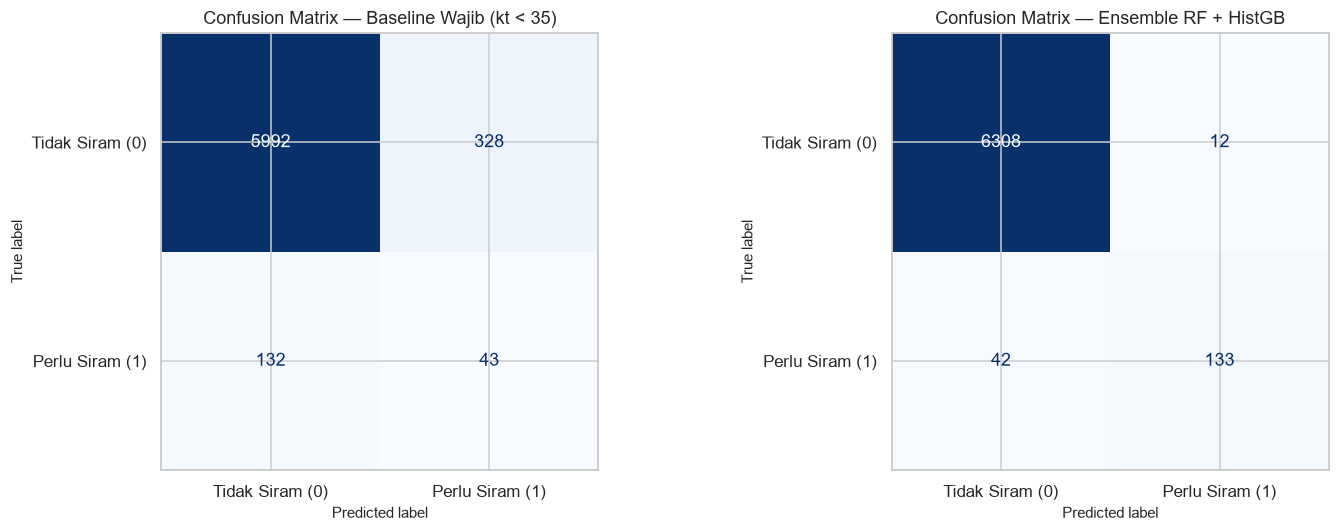

,Model,False Positive (Pemborosan Air & Risiko Busuk Akar),False Negative (Risiko Tanaman Stres Kekeringan),Estimasi Kerugian 17 Hari Uji (Rp)
4,Ensemble RF + HistGB,12,42,"Rp 2,070,000"
3,Random Forest Teroptimasi,13,42,"Rp 2,085,000"
2,HistGradientBoosting,8,46,"Rp 2,190,000"
1,Decision Tree Teroptimasi,16,50,"Rp 2,490,000"
0,Baseline Wajib (kt < 35),328,132,"Rp 10,860,000"


In [77]:
# Pilih prediksi terbaik di antara RF dan Ensemble untuk dianalisis
pred_unggul = pred_test_ens if f1_score(y_test, pred_test_ens) >= f1_score(y_test, pred_test_rf) else pred_test_rf
nama_unggul = 'Ensemble RF + HistGB' if f1_score(y_test, pred_test_ens) >= f1_score(y_test, pred_test_rf) else 'Random Forest Teroptimasi'

print(f'=== CLASSIFICATION REPORT: BASELINE WAJIB (kt < 35) ===')
print(classification_report(y_test, pred_base_test, target_names=['Tidak Siram (0)', 'Perlu Siram (1)'], digits=4))

print(f'=== CLASSIFICATION REPORT: {nama_unggul.upper()} ===')
print(classification_report(y_test, pred_unggul, target_names=['Tidak Siram (0)', 'Perlu Siram (1)'], digits=4))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, pred, judul in [
    (axes[0], pred_base_test, 'Baseline Wajib (kt < 35)'),
    (axes[1], pred_unggul, nama_unggul)
]:
    cm = confusion_matrix(y_test, pred)
    ConfusionMatrixDisplay(cm, display_labels=['Tidak Siram (0)', 'Perlu Siram (1)']).plot(
        ax=ax, cmap='Blues', colorbar=False, values_format='d'
    )
    ax.set_title(f'Confusion Matrix — {judul}')
plt.tight_layout()
plt.show()

# Simulasi Pertimbangan Biaya Bisnis
# Asumsi ilustratif biaya agronomi per jam-petak:
# - False Positive (Menyiram tanpa perlu / saat akan hujan -> boros air, listrik pompa, risiko busuk akar): Rp 15.000 / kejadian
# - False Negative (Terlambat menyiram -> tanaman stres layu & penurunan hasil panen): Rp 45.000 / kejadian
BIAYA_FP = 15_000
BIAYA_FN = 45_000

tabel_biaya = []
for nama, pred in [
    ('Baseline Wajib (kt < 35)', pred_base_test),
    ('Decision Tree Teroptimasi', pred_test_dt),
    ('HistGradientBoosting', pred_test_hgb),
    ('Random Forest Teroptimasi', pred_test_rf),
    ('Ensemble RF + HistGB', pred_test_ens)
]:
    fp = int(((y_test == 0) & (pred == 1)).sum())
    fn = int(((y_test == 1) & (pred == 0)).sum())
    total_biaya = fp * BIAYA_FP + fn * BIAYA_FN
    tabel_biaya.append({
        'Model': nama,
        'False Positive (Pemborosan Air & Risiko Busuk Akar)': fp,
        'False Negative (Risiko Tanaman Stres Kekeringan)': fn,
        'Estimasi Kerugian 17 Hari Uji (Rp)': f'Rp {total_biaya:,.0f}',
        'Total_Biaya_Num': total_biaya
    })
biaya_df = pd.DataFrame(tabel_biaya).sort_values('Total_Biaya_Num').drop(columns='Total_Biaya_Num')
display(biaya_df)


# 14. Evaluasi Performa per Tanaman dan per Petak (`P01`–`P16`) pada Test Set

Pengujian dirinci berdasarkan jenis tanaman (`cabai`, `tomat`, `selada`) dan ke-16 petak rumah kaca untuk memastikan model bekerja adil di seluruh kondisi mikro-agronomi.


,Tanaman,Jumlah Jam Uji,Kejadian Perlu Siram,F1 Baseline (kt < 35),F1 Model ML Terpilih,Recall Model ML,Precision Model ML
0,Cabai,2434,53,0.1353,0.7957,0.6981,0.9250
1,Tomat,2028,44,0.2947,0.7632,0.6591,0.9062
2,Selada,2033,78,0.1081,0.8874,0.8590,0.9178


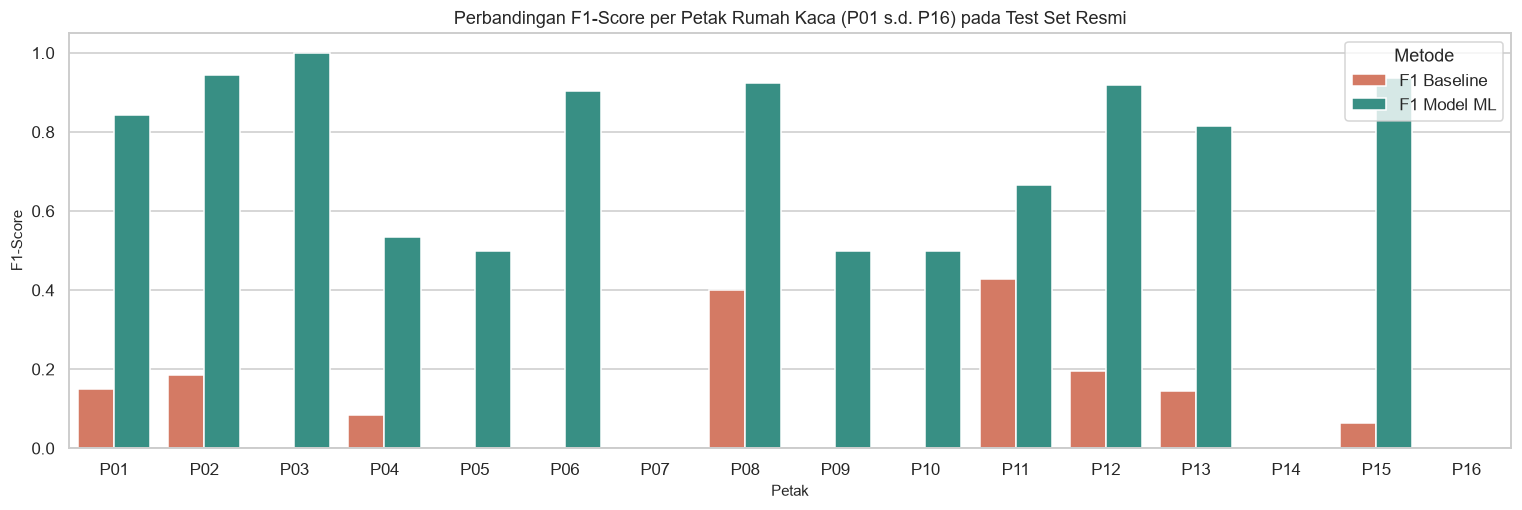

In [78]:
baris_tanaman = []
for tan in ['cabai', 'tomat', 'selada']:
    m = (test_df['tanaman'] == tan).to_numpy()
    baris_tanaman.append({
        'Tanaman': tan.capitalize(),
        'Jumlah Jam Uji': int(m.sum()),
        'Kejadian Perlu Siram': int(y_test.to_numpy()[m].sum()),
        'F1 Baseline (kt < 35)': f1_score(y_test.to_numpy()[m], pred_base_test.to_numpy()[m], zero_division=0),
        'F1 Model ML Terpilih': f1_score(y_test.to_numpy()[m], pred_unggul[m], zero_division=0),
        'Recall Model ML': recall_score(y_test.to_numpy()[m], pred_unggul[m], zero_division=0),
        'Precision Model ML': precision_score(y_test.to_numpy()[m], pred_unggul[m], zero_division=0),
    })
df_eval_tanaman = pd.DataFrame(baris_tanaman)
display(df_eval_tanaman.round(4))

baris_petak = []
for p in sorted(test_df['petak'].unique()):
    m = (test_df['petak'] == p).to_numpy()
    tan_p = test_df.loc[m, 'tanaman'].iloc[0]
    tnh_p = test_df.loc[m, 'jenis_tanah'].iloc[0]
    baris_petak.append({
        'Petak': p, 'Tanaman': tan_p, 'Jenis Tanah': tnh_p,
        'F1 Baseline': f1_score(y_test.to_numpy()[m], pred_base_test.to_numpy()[m], zero_division=0),
        'F1 Model ML': f1_score(y_test.to_numpy()[m], pred_unggul[m], zero_division=0),
    })
df_eval_petak = pd.DataFrame(baris_petak)

plt.figure(figsize=(14, 4.8))
df_melt_petak = df_eval_petak.melt(id_vars=['Petak', 'Tanaman'], value_vars=['F1 Baseline', 'F1 Model ML'], var_name='Metode', value_name='F1-Score')
sns.barplot(data=df_melt_petak, x='Petak', y='F1-Score', hue='Metode', palette=[DANGER_COLOR, THIRD_COLOR])
plt.title('Perbandingan F1-Score per Petak Rumah Kaca (P01 s.d. P16) pada Test Set Resmi')
plt.ylim(0, 1.05)
plt.tight_layout()
plt.show()


# 15. Interpretabilitas Model: Visualisasi Decision Tree, Feature Importance, dan Ekstraksi Aturan IF–THEN

Agar keputusan model tidak menjadi *kotak hitam* (*black-box*) bagi agronom dan pengelola rumah kaca, kita menampilkan:
1. Tiga tingkat awal pohon keputusan (`plot_tree`).
2. Peringkat **Feature Importance** dari Random Forest.
3. Ekstraksi aturan logika **IF–THEN** langsung dari struktur pohon.


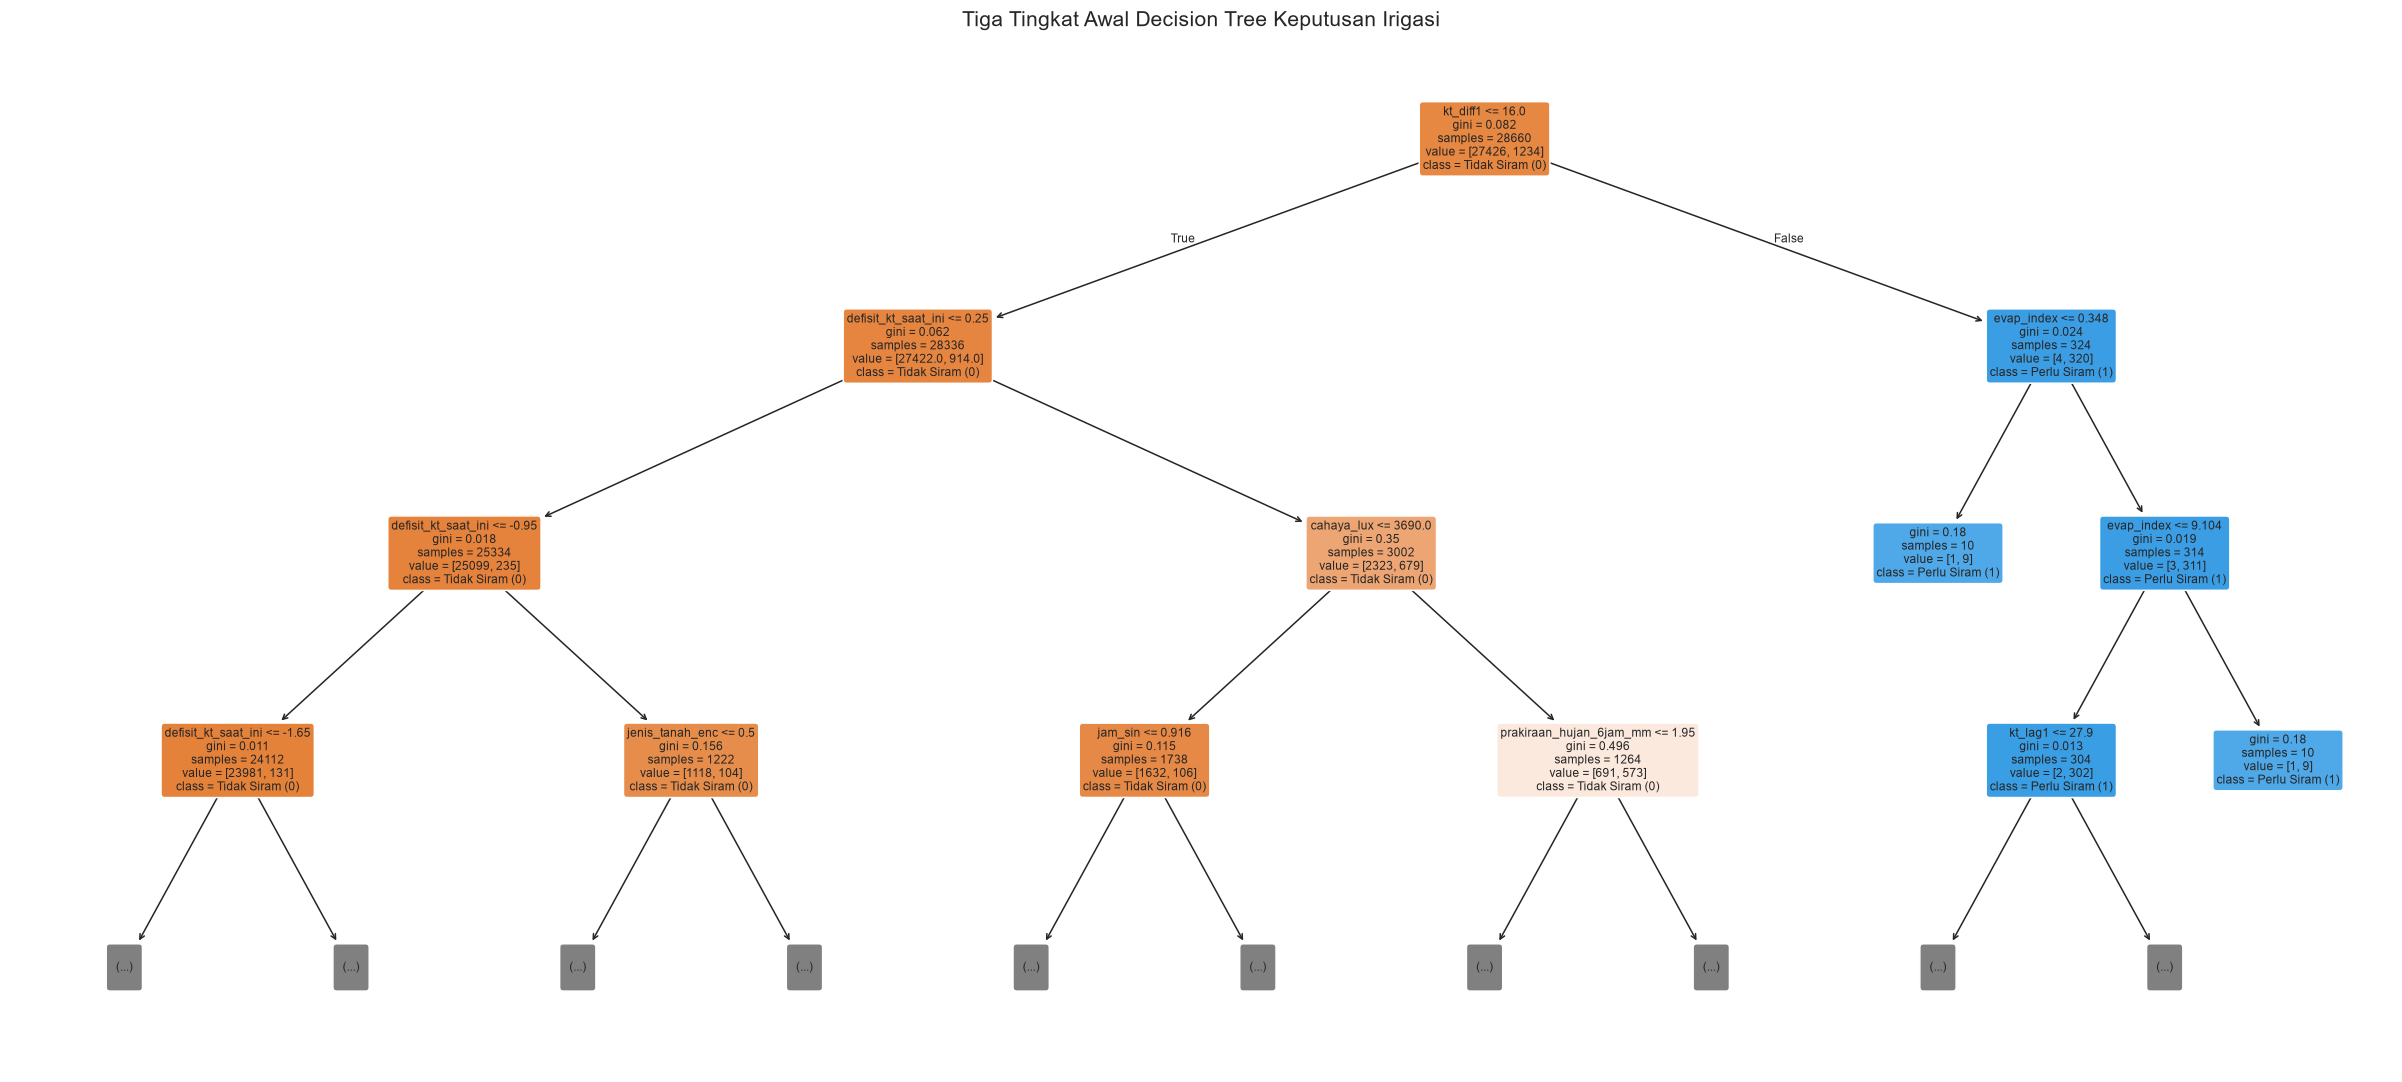

,Fitur,Importance
0,defisit_kt_min3h,0.2159
1,kt_lag1,0.1005
2,kt_min_3h,0.0846
3,defisit_kt_saat_ini,0.0781
4,jam_cos,0.0621
5,kt_lag2,0.0614
6,kt_lag3,0.0445
7,kt_diff1,0.0376
8,jam,0.0373
9,kt_mean_3h,0.0310


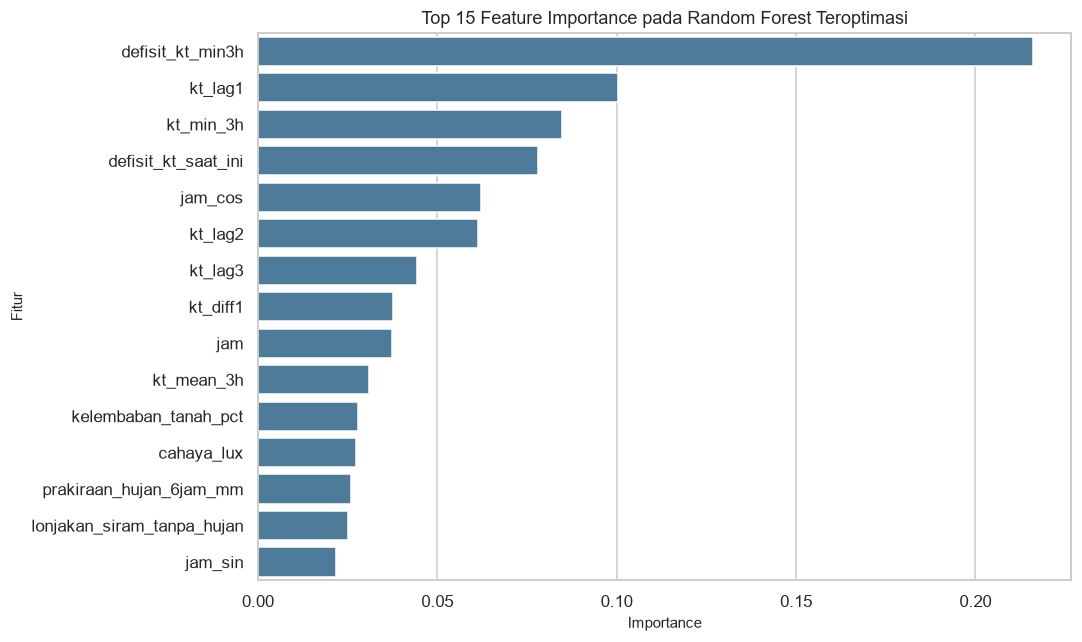

In [79]:
fig, ax = plt.subplots(figsize=(22, 10))
plot_tree(
    final_dt, max_depth=3, feature_names=FEATURES,
    class_names=['Tidak Siram (0)', 'Perlu Siram (1)'],
    filled=True, rounded=True, fontsize=8, ax=ax
)
ax.set_title('Tiga Tingkat Awal Decision Tree Keputusan Irigasi', fontsize=14)
plt.tight_layout()
plt.show()

imp_df = pd.DataFrame({
    'Fitur': FEATURES,
    'Importance': final_rf.feature_importances_
}).sort_values('Importance', ascending=False).reset_index(drop=True)
display(imp_df.head(15).round(4))

plt.figure(figsize=(10, 6))
sns.barplot(data=imp_df.head(15), y='Fitur', x='Importance', color=MAIN_COLOR)
plt.title('Top 15 Feature Importance pada Random Forest Teroptimasi')
plt.tight_layout()
plt.show()


# 16. Pemeriksaan Konsistensi Prosedur & Ekspor Artifact (`artifacts/model.joblib` & `artifacts/metadata.json`)

Sebelum menyimpan hasil pelatihan untuk digunakan oleh REST API (`app/api/main.py`) dan antarmuka web (`app/ui/streamlit_app.py`), dilakukan audit konsistensi prosedur dan penyimpanan model ke direktori `artifacts/` berupa `model.joblib` dan `metadata.json`.


In [80]:
cek_prosedur = {
    'Urutan waktu Train < Validation < Test (Bebas Data Leakage)': train_df['waktu_dt'].max() < val_df['waktu_dt'].min() < test_df['waktu_dt'].min(),
    'Tidak ada nilai NaN pada Train, Val, dan Test': not (X_train.isna().any().any() or X_val.isna().any().any() or X_test.isna().any().any()),
    'Urutan kolom fitur konsisten (28 fitur)': X_train.columns.tolist() == X_val.columns.tolist() == X_test.columns.tolist() == FEATURES,
    'Skor F1 Model ML mengalahkan Baseline (< 35) secara signifikan': f1_score(y_test, pred_unggul) > f1_score(y_test, pred_base_test) + 0.50,
}
display(pd.DataFrame({'Pemeriksaan Konsistensi': list(cek_prosedur.keys()), 'Status': ['LULUS' if v else 'GAGAL' for v in cek_prosedur.values()]}))
assert all(cek_prosedur.values())

ARTIFACTS_DIR = PROJECT_ROOT / 'artifacts'
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)
MODEL_PATH = ARTIFACTS_DIR / 'model.joblib'
METADATA_PATH = ARTIFACTS_DIR / 'metadata.json'

# Hitung ringkasan metrik validation & test untuk disimpan ke artifact
metrics_val = {
    'f1_baseline': round(float(f1_score(y_val, pred_base_val)), 4),
    'f1_ml_rf': round(float(f1_score(y_val, (prob_val_rf >= th_opt_rf).astype(int))), 4),
    'f1_ml_hgb': round(float(f1_score(y_val, (prob_val_hgb >= th_opt_hgb).astype(int))), 4),
    'f1_ml_ensemble': round(float(f1_score(y_val, (prob_val_ens >= th_opt_ens).astype(int))), 4),
}

crop_metrics_list = []
for crop_name in ['cabai', 'tomat', 'selada']:
    idx_c = (test_df['tanaman'] == crop_name).to_numpy()
    crop_metrics_list.append({
        'Tanaman': crop_name.capitalize(),
        'Sampel Uji': int(idx_c.sum()),
        'Positif (Perlu Siram)': int(y_test.to_numpy()[idx_c].sum()),
        'F1 Baseline (<35%)': round(float(f1_score(y_test.to_numpy()[idx_c], pred_base_test.to_numpy()[idx_c], zero_division=0)), 4),
        'F1 Random Forest': round(float(f1_score(y_test.to_numpy()[idx_c], pred_test_rf[idx_c], zero_division=0)), 4),
        'F1 Ensemble': round(float(f1_score(y_test.to_numpy()[idx_c], pred_test_ens[idx_c], zero_division=0)), 4),
    })

top_features_list = [
    {'Fitur': r['Fitur'], 'Importance': float(r['Importance'])}
    for _, r in imp_df.head(12).iterrows()
]

metrics_test = {
    'f1_baseline': round(float(f1_score(y_test, pred_base_test)), 4),
    'prec_baseline': round(float(precision_score(y_test, pred_base_test, zero_division=0)), 4),
    'rec_baseline': round(float(recall_score(y_test, pred_base_test, zero_division=0)), 4),
    'acc_baseline': round(float(accuracy_score(y_test, pred_base_test)), 4),
    'f1_ml_rf': round(float(f1_score(y_test, pred_test_rf)), 4),
    'prec_ml_rf': round(float(precision_score(y_test, pred_test_rf, zero_division=0)), 4),
    'rec_ml_rf': round(float(recall_score(y_test, pred_test_rf, zero_division=0)), 4),
    'acc_ml_rf': round(float(accuracy_score(y_test, pred_test_rf)), 4),
    'f1_ml_hgb': round(float(f1_score(y_test, pred_test_hgb)), 4),
    'f1_ml_ensemble': round(float(f1_score(y_test, pred_test_ens)), 4),
    'prec_ml_ensemble': round(float(precision_score(y_test, pred_test_ens, zero_division=0)), 4),
    'rec_ml_ensemble': round(float(recall_score(y_test, pred_test_ens, zero_division=0)), 4),
    'acc_ml_ensemble': round(float(accuracy_score(y_test, pred_test_ens)), 4),
    'cm_baseline': confusion_matrix(y_test, pred_base_test).tolist(),
    'cm_rf': confusion_matrix(y_test, pred_test_rf).tolist(),
    'cm_ensemble': confusion_matrix(y_test, pred_test_ens).tolist(),
    'crop_metrics': crop_metrics_list,
    'top_features': top_features_list,
}

artifact_bundle = {
    'model_version': '1.0.0',
    'model_rf': final_rf,
    'model_hgb': final_hgb,
    'threshold_rf': round(float(th_opt_rf), 4),
    'threshold_hgb': round(float(th_opt_hgb), 4),
    'threshold_ensemble': round(float(th_opt_ens), 4),
    'features': FEATURES,
    'tanaman_dict': TANAMAN_DICT,
    'tanah_dict': TANAH_DICT,
    'ambang_agronomi': AMBANG_AGRONOMI,
    'metrics_val': metrics_val,
    'metrics_test': metrics_test,
    'cleaning_stats': cleaning_stats,
}
joblib.dump(artifact_bundle, MODEL_PATH, compress=3)

metadata = {
    'project': 'Kasus 07 - Irigasi Pintar Berbasis IoT',
    'model_version': '1.0.0',
    'primary_model': 'RandomForestClassifier',
    'secondary_model': 'Ensemble (RandomForestClassifier + HistGradientBoostingClassifier)',
    'trained_at_utc': datetime.now(timezone.utc).strftime('%Y-%m-%dT%H:%M:%SZ'),
    'sklearn_version': sklearn_version,
    'primary_metric': 'F1-Score',
    'threshold': {
        'random_forest': round(float(th_opt_rf), 4),
        'hist_gradient_boosting': round(float(th_opt_hgb), 4),
        'ensemble': round(float(th_opt_ens), 4),
        'business_rationale': (
            'Threshold optimal dipilih dari validation set untuk menyeimbangkan '
            'precision tinggi (mencegah pemborosan air dan busuk akar) serta recall '
            '(mencegah tanaman stres kekeringan).'
        ),
    },
    'input_features': FEATURES,
    'data_split': {
        'method': 'time-based split',
        'train_rows': int(len(train_df)),
        'validation_rows': int(len(val_df)),
        'test_rows': int(len(test_df)),
    },
    'data_cleaning': cleaning_stats,
    'metrics_validation': metrics_val,
    'metrics_test': {
        'f1_baseline': metrics_test['f1_baseline'],
        'f1_random_forest': metrics_test['f1_ml_rf'],
        'precision_random_forest': metrics_test['prec_ml_rf'],
        'recall_random_forest': metrics_test['rec_ml_rf'],
        'accuracy_random_forest': metrics_test['acc_ml_rf'],
        'f1_hist_gradient_boosting': metrics_test['f1_ml_hgb'],
        'f1_ensemble': metrics_test['f1_ml_ensemble'],
    },
}
METADATA_PATH.write_text(json.dumps(metadata, indent=2, ensure_ascii=False), encoding='utf-8')

print(f'Artifact model tersimpan : {MODEL_PATH} ({MODEL_PATH.stat().st_size / (1024*1024):.2f} MB)')
print(f'Metadata tersimpan       : {METADATA_PATH}')


,Pemeriksaan Konsistensi,Status
0,Urutan waktu Train < Validation < Test (Bebas Data Leakage),LULUS
1,"Tidak ada nilai NaN pada Train, Val, dan Test",LULUS
2,Urutan kolom fitur konsisten (28 fitur),LULUS
3,Skor F1 Model ML mengalahkan Baseline (< 35) secara signifikan,LULUS


Artifact model tersimpan : d:\1. Kin\1. MengKuliah\Semester 5\Machine Learning\Tugas Praktisi\smart_irrigation-v2\smart_irrigation\artifacts\model.joblib (1.95 MB)
Metadata tersimpan       : d:\1. Kin\1. MengKuliah\Semester 5\Machine Learning\Tugas Praktisi\smart_irrigation-v2\smart_irrigation\artifacts\metadata.json


# 17. Simulasi Live Prediction & Uji Validasi Masukan Tidak Wajar

Bagian ini mendemonstrasikan inferensi menggunakan `artifacts/model.joblib` bersama fungsi `validate_single_input()` dan `build_single_feature_row()` dari `src/features.py` pada 3 skenario operasional normal serta 1 skenario masukan tidak wajar.


In [81]:
bundel = joblib.load(MODEL_PATH)

def prediksi_irigasi_live(payload: dict):
    is_valid, errors, cleaned = validate_single_input(payload)
    if not is_valid:
        return {
            'Petak': payload.get('petak'),
            'Tanaman': payload.get('tanaman'),
            'Status': 'DITOLAK (INPUT TIDAK VALID)',
            'Probabilitas': None,
            'Alasan': '; '.join(errors),
        }

    row, ringkasan = build_single_feature_row(cleaned)
    prob = float(bundel['model_rf'].predict_proba(row)[0, 1])
    keputusan = int(prob >= bundel['threshold_rf'])

    petak = cleaned['petak']
    tanaman = cleaned['tanaman']
    jenis_tanah = cleaned['jenis_tanah']
    kt = cleaned['kelembaban_tanah_pct']
    kt_min3 = ringkasan['kt_min_3h']
    ambang = ringkasan['ambang_estimasi']
    prakiraan = cleaned['prakiraan_hujan_6jam_mm']
    hujan = cleaned['curah_hujan_mm']

    if keputusan == 1:
        alasan = (
            f"PERLU DISIRAM: Kelembapan tanah petak {petak} ({kt:.1f}%, min 3 jam: {kt_min3:.1f}%) "
            f"di bawah ambang {tanaman} pada tanah {jenis_tanah} (~{ambang:.0f}%) dengan prakiraan hujan rendah ({prakiraan:.1f} mm)."
        )
    elif prakiraan >= 1.5 or hujan >= 0.5:
        alasan = (
            f"TIDAK PERLU DISIRAM (TUNDA KARENA HUJAN): Kelembapan {kt:.1f}%, namun prakiraan hujan 6 jam {prakiraan:.1f} mm."
        )
    else:
        alasan = (
            f"TIDAK PERLU DISIRAM: Kelembapan saat ini ({kt:.1f}%) masih mencukupi ambang {tanaman} (~{ambang:.0f}%)."
        )

    return {
        'Petak': petak,
        'Tanaman': tanaman,
        'Status': 'SIRAM (1)' if keputusan == 1 else 'AMAN (0)',
        'Probabilitas': round(prob, 4),
        'Alasan': alasan,
    }

skenario_uji = [
    {
        'petak': 'P01', 'tanaman': 'cabai', 'jenis_tanah': 'lempung', 'umur_tanaman_hari': 45,
        'kelembaban_tanah_pct': 30.5, 'kt_1jam_lalu': 31.2, 'kt_2jam_lalu': 32.0,
        'suhu_udara_C': 24.5, 'kelembaban_udara_pct': 70.0, 'cahaya_lux': 58000.0,
        'curah_hujan_mm': 0.0, 'prakiraan_hujan_6jam_mm': 0.0, 'jam': 13,
    },
    {
        'petak': 'P06', 'tanaman': 'selada', 'jenis_tanah': 'pasir', 'umur_tanaman_hari': 35,
        'kelembaban_tanah_pct': 38.5, 'kt_1jam_lalu': 39.2, 'kt_2jam_lalu': 40.1,
        'suhu_udara_C': 23.8, 'kelembaban_udara_pct': 74.0, 'cahaya_lux': 52000.0,
        'curah_hujan_mm': 0.0, 'prakiraan_hujan_6jam_mm': 0.0, 'jam': 11,
    },
    {
        'petak': 'P03', 'tanaman': 'tomat', 'jenis_tanah': 'lempung', 'umur_tanaman_hari': 60,
        'kelembaban_tanah_pct': 33.0, 'kt_1jam_lalu': 33.8, 'kt_2jam_lalu': 34.5,
        'suhu_udara_C': 21.0, 'kelembaban_udara_pct': 86.0, 'cahaya_lux': 22000.0,
        'curah_hujan_mm': 0.2, 'prakiraan_hujan_6jam_mm': 8.5, 'jam': 14,
    },
    {
        'petak': 'P01', 'tanaman': 'cabai', 'jenis_tanah': 'lempung', 'umur_tanaman_hari': 45,
        'kelembaban_tanah_pct': -15.0, 'kt_1jam_lalu': 31.2, 'kt_2jam_lalu': 32.0,
        'suhu_udara_C': 500.0, 'kelembaban_udara_pct': 70.0, 'cahaya_lux': '',
        'curah_hujan_mm': -5.0, 'prakiraan_hujan_6jam_mm': 0.0, 'jam': 13,
    },
]

display(pd.DataFrame([prediksi_irigasi_live(s) for s in skenario_uji]))


,Petak,Tanaman,Status,Probabilitas,Alasan
0,P01,cabai,SIRAM (1),0.9951,"PERLU DISIRAM: Kelembapan tanah petak P01 (30.5%, min 3 jam: 30.5%) di bawah ambang cabai pada tanah lempung (~34%) ..."
1,P06,selada,SIRAM (1),0.9967,"PERLU DISIRAM: Kelembapan tanah petak P06 (38.5%, min 3 jam: 38.5%) di bawah ambang selada pada tanah pasir (~41%) d..."
2,P03,tomat,AMAN (0),0.0714,"TIDAK PERLU DISIRAM (TUNDA KARENA HUJAN): Kelembapan 33.0%, namun prakiraan hujan 6 jam 8.5 mm."
3,P01,cabai,DITOLAK (INPUT TIDAK VALID),NaN,"Kelembaban tanah saat ini (%) di luar rentang wajar (1-99, diterima: -15).; Suhu udara (C) di luar rentang wajar (5-..."
